In [1]:
from pathlib import Path

ROOT = Path.cwd()
print("Current folder:", ROOT)

for p in sorted(ROOT.iterdir()):
    print(p.name)

Current folder: C:\Users\user\Desktop\M2\Sensors and Signals\Major Project\major project\final_experiment_data
.ipynb_checkpoints
00_calibration
__pycache__
boyuan_depth_results
depth_estimation_validation.py
depth_estimation_validation_submission.ipynb
Depth_Robustness_Analysis_Merged.ipynb
lightfield_processing_Yitong.ipynb.ipynb
quality_control
robustness_analysis_results
sessions
software
targets.csv
targets_history


In [4]:
SESSIONS = ROOT / "sessions"

for p in sorted(SESSIONS.iterdir()):
    if p.is_dir():
        print("\n", p.name)
        for sub in sorted(p.iterdir()):
            if sub.is_dir():
                print("   ", sub.name)


 lightfield
    geometry_grid_01
    lf_holdout_01
    lf_holdout_02
    lf_holdout_03
    lf_holdout_04
    lf_layers_3diff_01
    lf_layers_3same_01
    lf_layers_5obj_01
    lf_train_01
    lf_train_02
    lf_train_03
    lf_train_04

 reposition
    reposition_01

 snr
    snr_dark
    snr_textured
    snr_uniform_high
    snr_uniform_low
    snr_uniform_mid

 ssim_reference
    ssim_holdout_01
    ssim_holdout_02
    ssim_holdout_03
    ssim_holdout_04
    ssim_layers_3diff_01
    ssim_layers_3same_01
    ssim_layers_5obj_01
    ssim_train_01
    ssim_train_02
    ssim_train_03
    ssim_train_04


In [5]:
from collections import Counter

def count_files(folder):
    counts = Counter()
    for f in folder.rglob("*"):
        if f.is_file():
            counts[f.suffix.lower()] += 1
    return counts

for category in ["lightfield", "reposition", "snr", "ssim_reference"]:
    category_path = SESSIONS / category
    print(f"\n=== {category.upper()} ===")
    
    for session in sorted(category_path.iterdir()):
        if session.is_dir():
            counts = count_files(session)
            print(
                f"{session.name:25s} "
                f"DNG={counts['.dng']:3d}  "
                f"PNG={counts['.png']:3d}  "
                f"JSON={counts['.json']:3d}  "
                f"CSV={counts['.csv']:3d}"
            )


=== LIGHTFIELD ===
geometry_grid_01          DNG= 30  PNG= 10  JSON=  1  CSV=  1
lf_holdout_01             DNG= 30  PNG= 10  JSON=  1  CSV=  1
lf_holdout_02             DNG= 30  PNG= 10  JSON=  1  CSV=  1
lf_holdout_03             DNG= 30  PNG= 10  JSON=  1  CSV=  1
lf_holdout_04             DNG= 30  PNG= 10  JSON=  1  CSV=  1
lf_layers_3diff_01        DNG= 30  PNG= 10  JSON=  1  CSV=  1
lf_layers_3same_01        DNG= 30  PNG= 10  JSON=  1  CSV=  1
lf_layers_5obj_01         DNG= 30  PNG= 10  JSON=  1  CSV=  1
lf_train_01               DNG= 30  PNG= 10  JSON=  1  CSV=  1
lf_train_02               DNG= 30  PNG= 10  JSON=  1  CSV=  1
lf_train_03               DNG= 30  PNG= 10  JSON=  1  CSV=  1
lf_train_04               DNG= 30  PNG= 10  JSON=  1  CSV=  1

=== REPOSITION ===
reposition_01             DNG= 30  PNG= 15  JSON=  1  CSV=  1

=== SNR ===
snr_dark                  DNG= 24  PNG=  1  JSON=  1  CSV=  1
snr_textured              DNG= 24  PNG=  1  JSON=  1  CSV=  1
snr_uniform_high 

In [6]:
import pandas as pd

lightfield_root = SESSIONS / "lightfield"

for session in sorted(lightfield_root.iterdir()):
    if not session.is_dir():
        continue

    manifest = session / "manifest.csv"

    print("\n" + "=" * 70)
    print(session.name)

    if manifest.exists():
        df = pd.read_csv(manifest)
        print("Shape:", df.shape)
        print("Columns:", list(df.columns))
        display(df.head(10))
    else:
        print("No manifest.csv found")


geometry_grid_01
Shape: (30, 34)
Columns: ['step_id', 'mode', 'cycle_index', 'position_index', 'repeat_index', 'nominal_x_mm', 'x_mm', 'timestamp_utc', 'filename', 'bytes', 'sha256', 'exposure_us_requested', 'gain_requested', 'ae_requested', 'actual_exposure_us', 'actual_gain', 'frame_duration_us', 'sensor_timestamp_ns', 'capture_metadata_source', 'raw_height', 'raw_width', 'black_levels_dn', 'white_level_dn', 'min_dn', 'median_dn', 'p99_dn', 'max_dn', 'saturated_pct', 'near_black_pct', 'scene_condition', 'reference_kind', 'moved_away_and_returned', 'notes', 'recovered_orphan']


,step_id,mode,cycle_index,position_index,repeat_index,nominal_x_mm,x_mm,timestamp_utc,filename,bytes,...,median_dn,p99_dn,max_dn,saturated_pct,near_black_pct,scene_condition,reference_kind,moved_away_and_returned,notes,recovered_orphan
0,1,lightfield,1,1,1,0.0,0.0,2026-10-23T02:59:44.603331+00:00,raw/step_001_x+0000.000mm_cycle01_rep001.dng,2592736,...,492.0,835.0,1023,0.012924,0.000000,textured,NaN,False,NaN,False
1,1,lightfield,1,1,2,0.0,0.0,2026-10-23T02:59:46.029976+00:00,raw/step_001_x+0000.000mm_cycle01_rep002.dng,2592736,...,492.0,834.0,1023,0.013262,0.000048,textured,NaN,False,NaN,False
2,1,lightfield,1,1,3,0.0,0.0,2026-10-23T02:59:47.408692+00:00,raw/step_001_x+0000.000mm_cycle01_rep003.dng,2592736,...,492.0,834.0,1023,0.013117,0.000000,textured,NaN,False,NaN,False
3,2,lightfield,1,2,1,20.0,20.0,2026-10-23T03:00:04.670508+00:00,raw/step_002_x+0020.000mm_cycle01_rep001.dng,2592736,...,501.0,847.0,1023,0.011188,0.000000,textured,NaN,False,NaN,False
4,2,lightfield,1,2,2,20.0,20.0,2026-10-23T03:00:06.073797+00:00,raw/step_002_x+0020.000mm_cycle01_rep002.dng,2592736,...,501.0,847.0,1023,0.012056,0.000000,textured,NaN,False,NaN,False
5,2,lightfield,1,2,3,20.0,20.0,2026-10-23T03:00:07.298873+00:00,raw/step_002_x+0020.000mm_cycle01_rep003.dng,2592736,...,495.0,838.0,1023,0.011912,0.000000,textured,NaN,False,NaN,False
6,3,lightfield,1,3,1,40.0,40.0,2026-10-23T03:00:21.610222+00:00,raw/step_003_x+0040.000mm_cycle01_rep001.dng,2592736,...,495.0,840.0,1023,0.011960,0.000000,textured,NaN,False,NaN,False
7,3,lightfield,1,3,2,40.0,40.0,2026-10-23T03:00:23.043185+00:00,raw/step_003_x+0040.000mm_cycle01_rep002.dng,2592736,...,495.0,839.0,1023,0.011960,0.000000,textured,NaN,False,NaN,False
8,3,lightfield,1,3,3,40.0,40.0,2026-10-23T03:00:24.246138+00:00,raw/step_003_x+0040.000mm_cycle01_rep003.dng,2592736,...,503.0,853.0,1023,0.012490,0.000000,textured,NaN,False,NaN,False
9,4,lightfield,1,4,1,60.0,60.0,2026-10-23T03:00:36.666300+00:00,raw/step_004_x+0060.000mm_cycle01_rep001.dng,2592736,...,494.0,834.0,1023,0.014564,0.000000,textured,NaN,False,NaN,False



lf_holdout_01
Shape: (30, 34)
Columns: ['step_id', 'mode', 'cycle_index', 'position_index', 'repeat_index', 'nominal_x_mm', 'x_mm', 'timestamp_utc', 'filename', 'bytes', 'sha256', 'exposure_us_requested', 'gain_requested', 'ae_requested', 'actual_exposure_us', 'actual_gain', 'frame_duration_us', 'sensor_timestamp_ns', 'capture_metadata_source', 'raw_height', 'raw_width', 'black_levels_dn', 'white_level_dn', 'min_dn', 'median_dn', 'p99_dn', 'max_dn', 'saturated_pct', 'near_black_pct', 'scene_condition', 'reference_kind', 'moved_away_and_returned', 'notes', 'recovered_orphan']


,step_id,mode,cycle_index,position_index,repeat_index,nominal_x_mm,x_mm,timestamp_utc,filename,bytes,...,median_dn,p99_dn,max_dn,saturated_pct,near_black_pct,scene_condition,reference_kind,moved_away_and_returned,notes,recovered_orphan
0,1,lightfield,1,1,1,0.0,0.0,2026-10-23T03:54:32.814997+00:00,raw/step_001_x+0000.000mm_cycle01_rep001.dng,2592736,...,453.0,791.0,936,0.000000,0.0,textured,NaN,False,NaN,False
1,1,lightfield,1,1,2,0.0,0.0,2026-10-23T03:54:34.311997+00:00,raw/step_001_x+0000.000mm_cycle01_rep002.dng,2592736,...,452.0,792.0,917,0.000000,0.0,textured,NaN,False,NaN,False
2,1,lightfield,1,1,3,0.0,0.0,2026-10-23T03:54:35.479286+00:00,raw/step_001_x+0000.000mm_cycle01_rep003.dng,2592736,...,452.0,792.0,934,0.000000,0.0,textured,NaN,False,NaN,False
3,2,lightfield,1,2,1,20.0,20.0,2026-10-23T03:54:46.783705+00:00,raw/step_002_x+0020.000mm_cycle01_rep001.dng,2592736,...,453.0,793.0,923,0.000000,0.0,textured,NaN,False,NaN,False
4,2,lightfield,1,2,2,20.0,20.0,2026-10-23T03:54:48.230741+00:00,raw/step_002_x+0020.000mm_cycle01_rep002.dng,2592736,...,453.0,792.0,932,0.000000,0.0,textured,NaN,False,NaN,False
5,2,lightfield,1,2,3,20.0,20.0,2026-10-23T03:54:49.389565+00:00,raw/step_002_x+0020.000mm_cycle01_rep003.dng,2592736,...,454.0,792.0,967,0.000000,0.0,textured,NaN,False,NaN,False
6,3,lightfield,1,3,1,40.0,40.0,2026-10-23T03:55:23.715898+00:00,raw/step_003_x+0040.000mm_cycle01_rep001.dng,2592736,...,452.0,789.0,957,0.000000,0.0,textured,NaN,False,NaN,False
7,3,lightfield,1,3,2,40.0,40.0,2026-10-23T03:55:25.267308+00:00,raw/step_003_x+0040.000mm_cycle01_rep002.dng,2592736,...,452.0,788.0,987,0.000000,0.0,textured,NaN,False,NaN,False
8,3,lightfield,1,3,3,40.0,40.0,2026-10-23T03:55:26.585968+00:00,raw/step_003_x+0040.000mm_cycle01_rep003.dng,2592736,...,452.0,788.0,981,0.000000,0.0,textured,NaN,False,NaN,False
9,4,lightfield,1,4,1,60.0,60.0,2026-10-23T03:55:37.080655+00:00,raw/step_004_x+0060.000mm_cycle01_rep001.dng,2592736,...,452.0,788.0,1023,0.000723,0.0,textured,NaN,False,NaN,False



lf_holdout_02
Shape: (30, 34)
Columns: ['step_id', 'mode', 'cycle_index', 'position_index', 'repeat_index', 'nominal_x_mm', 'x_mm', 'timestamp_utc', 'filename', 'bytes', 'sha256', 'exposure_us_requested', 'gain_requested', 'ae_requested', 'actual_exposure_us', 'actual_gain', 'frame_duration_us', 'sensor_timestamp_ns', 'capture_metadata_source', 'raw_height', 'raw_width', 'black_levels_dn', 'white_level_dn', 'min_dn', 'median_dn', 'p99_dn', 'max_dn', 'saturated_pct', 'near_black_pct', 'scene_condition', 'reference_kind', 'moved_away_and_returned', 'notes', 'recovered_orphan']


,step_id,mode,cycle_index,position_index,repeat_index,nominal_x_mm,x_mm,timestamp_utc,filename,bytes,...,median_dn,p99_dn,max_dn,saturated_pct,near_black_pct,scene_condition,reference_kind,moved_away_and_returned,notes,recovered_orphan
0,1,lightfield,1,1,1,0.0,0.0,2026-10-23T04:32:36.813247+00:00,raw/step_001_x+0000.000mm_cycle01_rep001.dng,2592736,...,460.0,803.0,949,0.000000,0.0,textured,NaN,False,NaN,False
1,1,lightfield,1,1,2,0.0,0.0,2026-10-23T04:32:38.421527+00:00,raw/step_001_x+0000.000mm_cycle01_rep002.dng,2592736,...,460.0,803.0,962,0.000000,0.0,textured,NaN,False,NaN,False
2,1,lightfield,1,1,3,0.0,0.0,2026-10-23T04:32:39.687278+00:00,raw/step_001_x+0000.000mm_cycle01_rep003.dng,2592736,...,460.0,803.0,958,0.000000,0.0,textured,NaN,False,NaN,False
3,2,lightfield,1,2,1,20.0,20.0,2026-10-23T04:32:51.837510+00:00,raw/step_002_x+0020.000mm_cycle01_rep001.dng,2592736,...,460.0,803.0,974,0.000000,0.0,textured,NaN,False,NaN,False
4,2,lightfield,1,2,2,20.0,20.0,2026-10-23T04:32:53.348401+00:00,raw/step_002_x+0020.000mm_cycle01_rep002.dng,2592736,...,460.0,803.0,951,0.000000,0.0,textured,NaN,False,NaN,False
5,2,lightfield,1,2,3,20.0,20.0,2026-10-23T04:32:54.560067+00:00,raw/step_002_x+0020.000mm_cycle01_rep003.dng,2592736,...,460.0,803.0,945,0.000000,0.0,textured,NaN,False,NaN,False
6,3,lightfield,1,3,1,40.0,40.0,2026-10-23T04:33:15.875489+00:00,raw/step_003_x+0040.000mm_cycle01_rep001.dng,2592736,...,463.0,808.0,1023,0.000048,0.0,textured,NaN,False,NaN,False
7,3,lightfield,1,3,2,40.0,40.0,2026-10-23T04:33:17.609910+00:00,raw/step_003_x+0040.000mm_cycle01_rep002.dng,2592736,...,464.0,810.0,1003,0.000000,0.0,textured,NaN,False,NaN,False
8,3,lightfield,1,3,3,40.0,40.0,2026-10-23T04:33:18.781172+00:00,raw/step_003_x+0040.000mm_cycle01_rep003.dng,2592736,...,465.0,811.0,1010,0.000000,0.0,textured,NaN,False,NaN,False
9,4,lightfield,1,4,1,60.0,60.0,2026-10-23T04:33:35.992703+00:00,raw/step_004_x+0060.000mm_cycle01_rep001.dng,2592736,...,493.0,853.0,1023,0.001784,0.0,textured,NaN,False,NaN,False


... (14 outputs left out)


lf_train_03
Shape: (30, 34)
Columns: ['step_id', 'mode', 'cycle_index', 'position_index', 'repeat_index', 'nominal_x_mm', 'x_mm', 'timestamp_utc', 'filename', 'bytes', 'sha256', 'exposure_us_requested', 'gain_requested', 'ae_requested', 'actual_exposure_us', 'actual_gain', 'frame_duration_us', 'sensor_timestamp_ns', 'capture_metadata_source', 'raw_height', 'raw_width', 'black_levels_dn', 'white_level_dn', 'min_dn', 'median_dn', 'p99_dn', 'max_dn', 'saturated_pct', 'near_black_pct', 'scene_condition', 'reference_kind', 'moved_away_and_returned', 'notes', 'recovered_orphan']


,step_id,mode,cycle_index,position_index,repeat_index,nominal_x_mm,x_mm,timestamp_utc,filename,bytes,...,median_dn,p99_dn,max_dn,saturated_pct,near_black_pct,scene_condition,reference_kind,moved_away_and_returned,notes,recovered_orphan
0,1,lightfield,1,1,1,0.0,0.0,2026-10-23T04:38:48.094297+00:00,raw/step_001_x+0000.000mm_cycle01_rep001.dng,2592736,...,471.0,822.0,1023,0.000048,0.0,textured,NaN,False,NaN,False
1,1,lightfield,1,1,2,0.0,0.0,2026-10-23T04:38:49.603454+00:00,raw/step_001_x+0000.000mm_cycle01_rep002.dng,2592736,...,474.0,827.0,975,0.000000,0.0,textured,NaN,False,NaN,False
2,1,lightfield,1,1,3,0.0,0.0,2026-10-23T04:38:50.899597+00:00,raw/step_001_x+0000.000mm_cycle01_rep003.dng,2592736,...,474.0,828.0,996,0.000000,0.0,textured,NaN,False,NaN,False
3,2,lightfield,1,2,1,20.0,20.0,2026-10-23T04:39:02.540887+00:00,raw/step_002_x+0020.000mm_cycle01_rep001.dng,2592736,...,468.0,818.0,970,0.000000,0.0,textured,NaN,False,NaN,False
4,2,lightfield,1,2,2,20.0,20.0,2026-10-23T04:39:04.112989+00:00,raw/step_002_x+0020.000mm_cycle01_rep002.dng,2592736,...,467.0,817.0,995,0.000000,0.0,textured,NaN,False,NaN,False
5,2,lightfield,1,2,3,20.0,20.0,2026-10-23T04:39:05.519296+00:00,raw/step_002_x+0020.000mm_cycle01_rep003.dng,2592736,...,466.0,816.0,1006,0.000000,0.0,textured,NaN,False,NaN,False
6,3,lightfield,1,3,1,40.0,40.0,2026-10-23T04:39:15.824295+00:00,raw/step_003_x+0040.000mm_cycle01_rep001.dng,2592736,...,464.0,813.0,1005,0.000000,0.0,textured,NaN,False,NaN,False
7,3,lightfield,1,3,2,40.0,40.0,2026-10-23T04:39:17.352897+00:00,raw/step_003_x+0040.000mm_cycle01_rep002.dng,2592736,...,465.0,814.0,1000,0.000000,0.0,textured,NaN,False,NaN,False
8,3,lightfield,1,3,3,40.0,40.0,2026-10-23T04:39:18.712271+00:00,raw/step_003_x+0040.000mm_cycle01_rep003.dng,2592736,...,464.0,814.0,997,0.000000,0.0,textured,NaN,False,NaN,False
9,4,lightfield,1,4,1,60.0,60.0,2026-10-23T04:39:29.129147+00:00,raw/step_004_x+0060.000mm_cycle01_rep001.dng,2592736,...,463.0,806.0,1023,0.000868,0.0,textured,NaN,False,NaN,False



lf_train_04
Shape: (30, 34)
Columns: ['step_id', 'mode', 'cycle_index', 'position_index', 'repeat_index', 'nominal_x_mm', 'x_mm', 'timestamp_utc', 'filename', 'bytes', 'sha256', 'exposure_us_requested', 'gain_requested', 'ae_requested', 'actual_exposure_us', 'actual_gain', 'frame_duration_us', 'sensor_timestamp_ns', 'capture_metadata_source', 'raw_height', 'raw_width', 'black_levels_dn', 'white_level_dn', 'min_dn', 'median_dn', 'p99_dn', 'max_dn', 'saturated_pct', 'near_black_pct', 'scene_condition', 'reference_kind', 'moved_away_and_returned', 'notes', 'recovered_orphan']


,step_id,mode,cycle_index,position_index,repeat_index,nominal_x_mm,x_mm,timestamp_utc,filename,bytes,...,median_dn,p99_dn,max_dn,saturated_pct,near_black_pct,scene_condition,reference_kind,moved_away_and_returned,notes,recovered_orphan
0,1,lightfield,1,1,1,0.0,0.0,2026-10-23T04:51:26.789842+00:00,raw/step_001_x+0000.000mm_cycle01_rep001.dng,2592736,...,495.0,863.0,1023,0.000048,0.0,textured,NaN,False,NaN,False
1,1,lightfield,1,1,2,0.0,0.0,2026-10-23T04:51:28.212713+00:00,raw/step_001_x+0000.000mm_cycle01_rep002.dng,2592736,...,491.0,858.0,1023,0.000048,0.0,textured,NaN,False,NaN,False
2,1,lightfield,1,1,3,0.0,0.0,2026-10-23T04:51:29.404861+00:00,raw/step_001_x+0000.000mm_cycle01_rep003.dng,2592736,...,491.0,857.0,1023,0.000048,0.0,textured,NaN,False,NaN,False
3,2,lightfield,1,2,1,20.0,20.0,2026-10-23T04:51:39.811057+00:00,raw/step_002_x+0020.000mm_cycle01_rep001.dng,2592736,...,494.0,857.0,1023,0.000096,0.0,textured,NaN,False,NaN,False
4,2,lightfield,1,2,2,20.0,20.0,2026-10-23T04:51:41.530880+00:00,raw/step_002_x+0020.000mm_cycle01_rep002.dng,2592736,...,491.0,852.0,1023,0.000048,0.0,textured,NaN,False,NaN,False
5,2,lightfield,1,2,3,20.0,20.0,2026-10-23T04:51:42.825181+00:00,raw/step_002_x+0020.000mm_cycle01_rep003.dng,2592736,...,491.0,852.0,1023,0.000193,0.0,textured,NaN,False,NaN,False
6,3,lightfield,1,3,1,40.0,40.0,2026-10-23T04:51:51.656070+00:00,raw/step_003_x+0040.000mm_cycle01_rep001.dng,2592736,...,489.0,854.0,1023,0.000482,0.0,textured,NaN,False,NaN,False
7,3,lightfield,1,3,2,40.0,40.0,2026-10-23T04:51:53.269949+00:00,raw/step_003_x+0040.000mm_cycle01_rep002.dng,2592736,...,493.0,859.0,1023,0.000482,0.0,textured,NaN,False,NaN,False
8,3,lightfield,1,3,3,40.0,40.0,2026-10-23T04:51:54.731179+00:00,raw/step_003_x+0040.000mm_cycle01_rep003.dng,2592736,...,492.0,858.0,1023,0.000482,0.0,textured,NaN,False,NaN,False
9,4,lightfield,1,4,1,60.0,60.0,2026-10-23T04:52:05.348557+00:00,raw/step_004_x+0060.000mm_cycle01_rep001.dng,2592736,...,473.0,831.0,1023,0.001109,0.0,textured,NaN,False,NaN,False


In [7]:
important_cols = [
    "position_index",
    "repeat_index",
    "nominal_x_mm",
    "x_mm",
    "filename",
    "actual_exposure_us",
    "actual_gain",
    "saturated_pct",
    "near_black_pct",
    "scene_condition",
    "notes"
]

sessions_to_check = [
    "geometry_grid_01",
    "lf_train_01",
    "lf_holdout_01",
    "lf_layers_3diff_01"
]

for name in sessions_to_check:
    manifest = lightfield_root / name / "manifest.csv"
    df = pd.read_csv(manifest)

    print("\n" + "=" * 90)
    print(name)

    existing_cols = [c for c in important_cols if c in df.columns]
    display(df[existing_cols].head(30))


geometry_grid_01


,position_index,repeat_index,nominal_x_mm,x_mm,filename,actual_exposure_us,actual_gain,saturated_pct,near_black_pct,scene_condition,notes
0,1,1,0.0,0.0,raw/step_001_x+0000.000mm_cycle01_rep001.dng,NaN,NaN,0.012924,0.000000,textured,NaN
1,1,2,0.0,0.0,raw/step_001_x+0000.000mm_cycle01_rep002.dng,NaN,NaN,0.013262,0.000048,textured,NaN
2,1,3,0.0,0.0,raw/step_001_x+0000.000mm_cycle01_rep003.dng,NaN,NaN,0.013117,0.000000,textured,NaN
3,2,1,20.0,20.0,raw/step_002_x+0020.000mm_cycle01_rep001.dng,NaN,NaN,0.011188,0.000000,textured,NaN
4,2,2,20.0,20.0,raw/step_002_x+0020.000mm_cycle01_rep002.dng,NaN,NaN,0.012056,0.000000,textured,NaN
5,2,3,20.0,20.0,raw/step_002_x+0020.000mm_cycle01_rep003.dng,NaN,NaN,0.011912,0.000000,textured,NaN
6,3,1,40.0,40.0,raw/step_003_x+0040.000mm_cycle01_rep001.dng,NaN,NaN,0.011960,0.000000,textured,NaN
7,3,2,40.0,40.0,raw/step_003_x+0040.000mm_cycle01_rep002.dng,NaN,NaN,0.011960,0.000000,textured,NaN
8,3,3,40.0,40.0,raw/step_003_x+0040.000mm_cycle01_rep003.dng,NaN,NaN,0.012490,0.000000,textured,NaN
9,4,1,60.0,60.0,raw/step_004_x+0060.000mm_cycle01_rep001.dng,NaN,NaN,0.014564,0.000000,textured,NaN



lf_train_01


,position_index,repeat_index,nominal_x_mm,x_mm,filename,actual_exposure_us,actual_gain,saturated_pct,near_black_pct,scene_condition,notes
0,1,1,0.0,0.0,raw/step_001_x+0000.000mm_cycle01_rep001.dng,NaN,NaN,0.000386,0.0,textured,NaN
1,1,2,0.0,0.0,raw/step_001_x+0000.000mm_cycle01_rep002.dng,NaN,NaN,0.000338,0.0,textured,NaN
2,1,3,0.0,0.0,raw/step_001_x+0000.000mm_cycle01_rep003.dng,NaN,NaN,0.000482,0.0,textured,NaN
3,2,1,20.0,20.0,raw/step_002_x+0020.000mm_cycle01_rep001.dng,NaN,NaN,0.000000,0.0,textured,NaN
4,2,2,20.0,20.0,raw/step_002_x+0020.000mm_cycle01_rep002.dng,NaN,NaN,0.000000,0.0,textured,NaN
5,2,3,20.0,20.0,raw/step_002_x+0020.000mm_cycle01_rep003.dng,NaN,NaN,0.000048,0.0,textured,NaN
6,3,1,40.0,40.0,raw/step_003_x+0040.000mm_cycle01_rep001.dng,NaN,NaN,0.000145,0.0,textured,NaN
7,3,2,40.0,40.0,raw/step_003_x+0040.000mm_cycle01_rep002.dng,NaN,NaN,0.000820,0.0,textured,NaN
8,3,3,40.0,40.0,raw/step_003_x+0040.000mm_cycle01_rep003.dng,NaN,NaN,0.000530,0.0,textured,NaN
9,4,1,60.0,60.0,raw/step_004_x+0060.000mm_cycle01_rep001.dng,NaN,NaN,0.003569,0.0,textured,NaN



lf_holdout_01


,position_index,repeat_index,nominal_x_mm,x_mm,filename,actual_exposure_us,actual_gain,saturated_pct,near_black_pct,scene_condition,notes
0,1,1,0.0,0.0,raw/step_001_x+0000.000mm_cycle01_rep001.dng,NaN,NaN,0.000000,0.0,textured,NaN
1,1,2,0.0,0.0,raw/step_001_x+0000.000mm_cycle01_rep002.dng,NaN,NaN,0.000000,0.0,textured,NaN
2,1,3,0.0,0.0,raw/step_001_x+0000.000mm_cycle01_rep003.dng,NaN,NaN,0.000000,0.0,textured,NaN
3,2,1,20.0,20.0,raw/step_002_x+0020.000mm_cycle01_rep001.dng,NaN,NaN,0.000000,0.0,textured,NaN
4,2,2,20.0,20.0,raw/step_002_x+0020.000mm_cycle01_rep002.dng,NaN,NaN,0.000000,0.0,textured,NaN
5,2,3,20.0,20.0,raw/step_002_x+0020.000mm_cycle01_rep003.dng,NaN,NaN,0.000000,0.0,textured,NaN
6,3,1,40.0,40.0,raw/step_003_x+0040.000mm_cycle01_rep001.dng,NaN,NaN,0.000000,0.0,textured,NaN
7,3,2,40.0,40.0,raw/step_003_x+0040.000mm_cycle01_rep002.dng,NaN,NaN,0.000000,0.0,textured,NaN
8,3,3,40.0,40.0,raw/step_003_x+0040.000mm_cycle01_rep003.dng,NaN,NaN,0.000000,0.0,textured,NaN
9,4,1,60.0,60.0,raw/step_004_x+0060.000mm_cycle01_rep001.dng,NaN,NaN,0.000723,0.0,textured,NaN



lf_layers_3diff_01


,position_index,repeat_index,nominal_x_mm,x_mm,filename,actual_exposure_us,actual_gain,saturated_pct,near_black_pct,scene_condition,notes
0,1,1,0.0,0.0,raw/step_001_x+0000.000mm_cycle01_rep001.dng,NaN,NaN,0.000000,0.000000,textured,NaN
1,1,2,0.0,0.0,raw/step_001_x+0000.000mm_cycle01_rep002.dng,NaN,NaN,0.000000,0.000048,textured,NaN
2,1,3,0.0,0.0,raw/step_001_x+0000.000mm_cycle01_rep003.dng,NaN,NaN,0.000000,0.000048,textured,NaN
3,2,1,20.0,20.0,raw/step_002_x+0020.000mm_cycle01_rep001.dng,NaN,NaN,0.000000,0.000048,textured,NaN
4,2,2,20.0,20.0,raw/step_002_x+0020.000mm_cycle01_rep002.dng,NaN,NaN,0.000000,0.000048,textured,NaN
5,2,3,20.0,20.0,raw/step_002_x+0020.000mm_cycle01_rep003.dng,NaN,NaN,0.000000,0.000048,textured,NaN
6,3,1,40.0,40.0,raw/step_003_x+0040.000mm_cycle01_rep001.dng,NaN,NaN,0.000000,0.000096,textured,NaN
7,3,2,40.0,40.0,raw/step_003_x+0040.000mm_cycle01_rep002.dng,NaN,NaN,0.000000,0.000048,textured,NaN
8,3,3,40.0,40.0,raw/step_003_x+0040.000mm_cycle01_rep003.dng,NaN,NaN,0.000000,0.000000,textured,NaN
9,4,1,60.0,60.0,raw/step_004_x+0060.000mm_cycle01_rep001.dng,NaN,NaN,0.000145,0.000048,textured,NaN


In [8]:
check_sessions = [
    "geometry_grid_01",
    "lf_train_01",
    "lf_holdout_01",
    "lf_layers_3diff_01"
]

for name in check_sessions:
    df = pd.read_csv(lightfield_root / name / "manifest.csv")

    print("\n" + "=" * 70)
    print(name)

    print("Positions:", sorted(df["x_mm"].unique()))
    print("Repeats per position:")
    print(df.groupby("x_mm")["repeat_index"].count().to_dict())

    print("Exposure values (us):", sorted(df["actual_exposure_us"].dropna().unique()))
    print("Gain values:", sorted(df["actual_gain"].dropna().unique()))

    print(
        "Saturation range (%):",
        df["saturated_pct"].min(),
        "to",
        df["saturated_pct"].max()
    )

    print(
        "Near-black range (%):",
        df["near_black_pct"].min(),
        "to",
        df["near_black_pct"].max()
    )


geometry_grid_01
Positions: [np.float64(0.0), np.float64(20.0), np.float64(40.0), np.float64(60.0), np.float64(80.0), np.float64(100.0), np.float64(120.0), np.float64(140.0), np.float64(160.0), np.float64(180.0)]
Repeats per position:
{0.0: 3, 20.0: 3, 40.0: 3, 60.0: 3, 80.0: 3, 100.0: 3, 120.0: 3, 140.0: 3, 160.0: 3, 180.0: 3}
Exposure values (us): []
Gain values: []
Saturation range (%): 0.011188 to 0.039159
Near-black range (%): 0.0 to 4.8e-05

lf_train_01
Positions: [np.float64(0.0), np.float64(20.0), np.float64(40.0), np.float64(60.0), np.float64(80.0), np.float64(100.0), np.float64(120.0), np.float64(140.0), np.float64(160.0), np.float64(180.0)]
Repeats per position:
{0.0: 3, 20.0: 3, 40.0: 3, 60.0: 3, 80.0: 3, 100.0: 3, 120.0: 3, 140.0: 3, 160.0: 3, 180.0: 3}
Exposure values (us): []
Gain values: []
Saturation range (%): 0.0 to 0.022039
Near-black range (%): 0.0 to 0.0

lf_holdout_01
Positions: [np.float64(0.0), np.float64(20.0), np.float64(40.0), np.float64(60.0), np.float64(8

In [9]:
for name in check_sessions:
    df = pd.read_csv(lightfield_root / name / "manifest.csv")

    print("\n" + "=" * 70)
    print(name)

    print(
        "Requested exposure (us):",
        sorted(df["exposure_us_requested"].dropna().unique())
    )

    print(
        "Requested gain:",
        sorted(df["gain_requested"].dropna().unique())
    )

    print(
        "AE requested:",
        sorted(df["ae_requested"].dropna().unique())
    )

    print(
        "Metadata source:",
        df["capture_metadata_source"].dropna().unique()
    )


geometry_grid_01
Requested exposure (us): [np.int64(32000)]
Requested gain: [np.float64(4.0)]
AE requested: [np.False_]
Metadata source: <ArrowStringArray>
['not available (requested settings only)']
Length: 1, dtype: str

lf_train_01
Requested exposure (us): [np.int64(32000)]
Requested gain: [np.float64(4.0)]
AE requested: [np.False_]
Metadata source: <ArrowStringArray>
['not available (requested settings only)']
Length: 1, dtype: str

lf_holdout_01
Requested exposure (us): [np.int64(32000)]
Requested gain: [np.float64(4.0)]
AE requested: [np.False_]
Metadata source: <ArrowStringArray>
['not available (requested settings only)']
Length: 1, dtype: str

lf_layers_3diff_01
Requested exposure (us): [np.int64(32000)]
Requested gain: [np.float64(4.0)]
AE requested: [np.False_]
Metadata source: <ArrowStringArray>
['not available (requested settings only)']
Length: 1, dtype: str


In [10]:
train_path = lightfield_root / "lf_train_01"

png_files = sorted(train_path.rglob("*.png"))

print("PNG count:", len(png_files))

for f in png_files:
    print(f.relative_to(train_path))

PNG count: 10
previews\step_001_x+0000.000mm_cycle01_rep001.png
previews\step_002_x+0020.000mm_cycle01_rep001.png
previews\step_003_x+0040.000mm_cycle01_rep001.png
previews\step_004_x+0060.000mm_cycle01_rep001.png
previews\step_005_x+0080.000mm_cycle01_rep001.png
previews\step_006_x+0100.000mm_cycle01_rep001.png
previews\step_007_x+0120.000mm_cycle01_rep001.png
previews\step_008_x+0140.000mm_cycle01_rep001.png
previews\step_009_x+0160.000mm_cycle01_rep001.png
previews\step_010_x+0180.000mm_cycle01_rep001.png


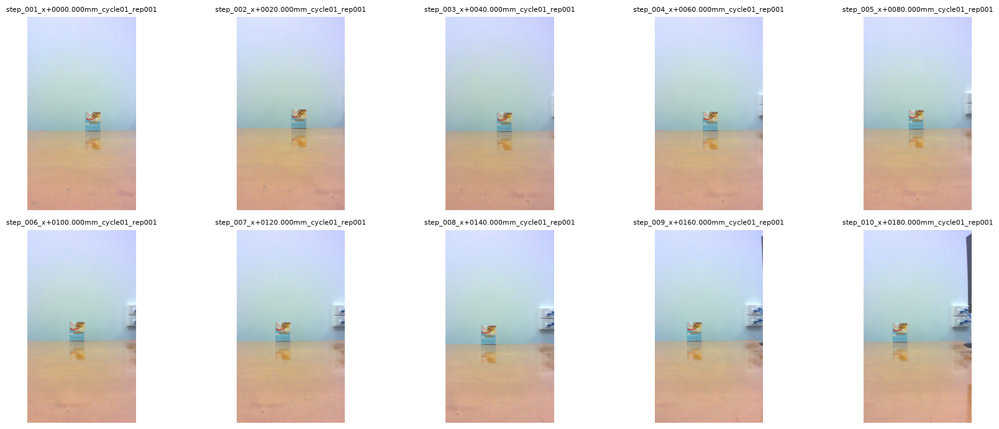

In [11]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for ax, f in zip(axes.ravel(), png_files):
    img = Image.open(f)
    ax.imshow(img)
    ax.set_title(f.stem, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

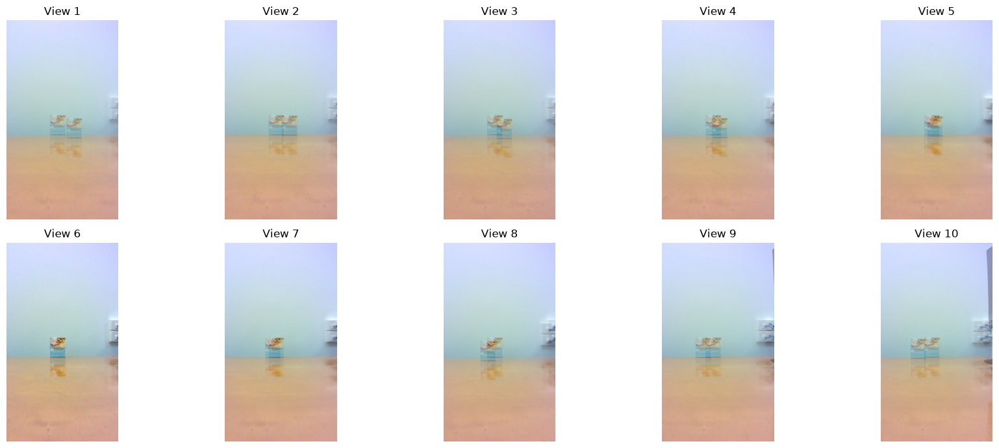

In [12]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Read the 10 preview images
images = [np.array(Image.open(f).convert("RGB")) for f in png_files]

# Use the middle viewpoint as reference
ref_idx = 5   # around x = 100 mm
ref = images[ref_idx]

fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for i, (ax, img) in enumerate(zip(axes.ravel(), images)):
    ax.imshow(ref)
    ax.imshow(img, alpha=0.5)
    ax.set_title(f"View {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [13]:
import cv2
import numpy as np
import pandas as pd

shift_results = []

for i in range(len(images) - 1):
    img1 = cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY).astype(np.float32)
    img2 = cv2.cvtColor(images[i + 1], cv2.COLOR_RGB2GRAY).astype(np.float32)

    # Phase correlation estimates translation between adjacent views
    (dx, dy), response = cv2.phaseCorrelate(img1, img2)

    shift_results.append({
        "view_pair": f"{i+1} -> {i+2}",
        "dx_pixels": dx,
        "dy_pixels": dy,
        "response": response
    })

shift_df = pd.DataFrame(shift_results)
display(shift_df)

,view_pair,dx_pixels,dy_pixels,response
0,1 -> 2,-0.393798,-0.048363,0.026883
1,2 -> 3,0.362897,-0.097635,0.052360
2,3 -> 4,0.250766,-0.335055,0.044573
3,4 -> 5,0.712181,0.323147,0.039097
4,5 -> 6,0.228264,-1.011483,0.032830
5,6 -> 7,0.525798,0.258394,0.129549
6,7 -> 8,0.367946,0.169674,0.064759
7,8 -> 9,0.139178,0.341881,0.020285
8,9 -> 10,0.166378,0.815441,0.041034


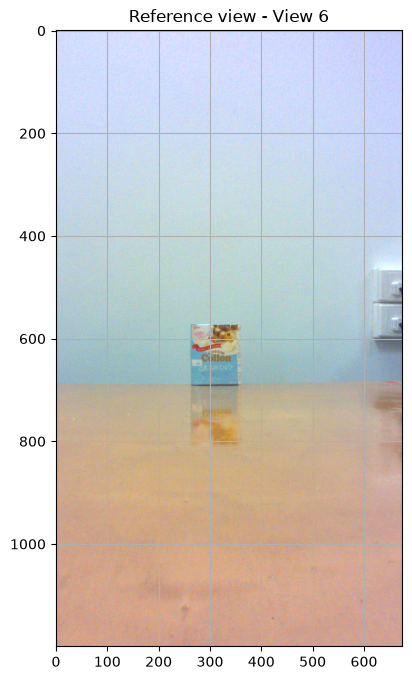

In [14]:
plt.figure(figsize=(6, 8))
plt.imshow(images[5])
plt.title("Reference view - View 6")
plt.axis("on")
plt.grid()
plt.show()

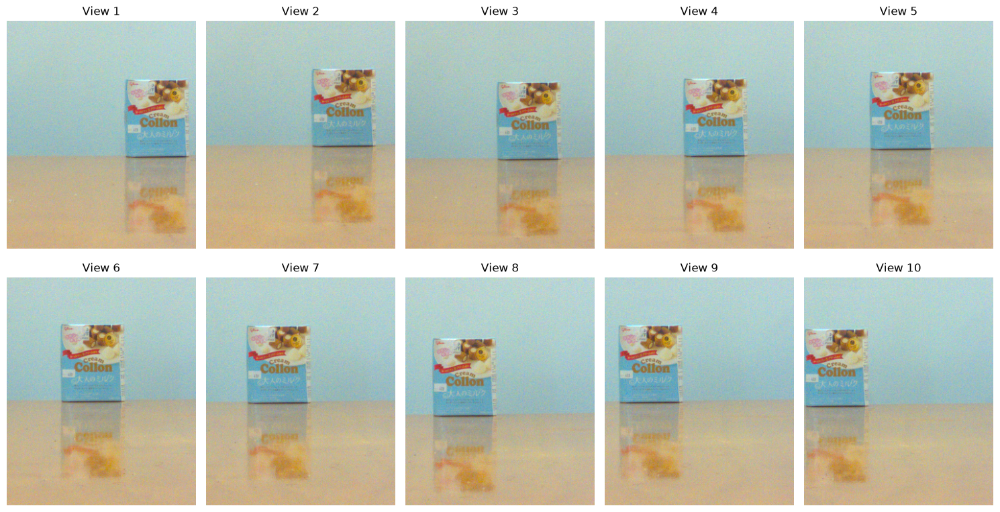

In [15]:
x1, x2 = 180, 470
y1, y2 = 500, 850

cropped_images = [
    img[y1:y2, x1:x2]
    for img in images
]

fig, axes = plt.subplots(2, 5, figsize=(15, 8))

for i, (ax, img) in enumerate(zip(axes.ravel(), cropped_images)):
    ax.imshow(img)
    ax.set_title(f"View {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
import cv2
import numpy as np

# Camera positions in mm
x_positions = np.arange(0, 200, 20, dtype=np.float32)  # 0,20,...,180
x_center = np.mean(x_positions)

def refocus_shift_average(images, x_positions, shift_per_mm):
    """
    images: list of RGB images with same shape
    x_positions: camera positions in mm
    shift_per_mm: horizontal image shift in pixels per mm
    """
    h, w, c = images[0].shape
    accumulator = np.zeros((h, w, c), dtype=np.float32)

    for img, x in zip(images, x_positions):
        shift_x = -shift_per_mm * (x - x_center)

        M = np.float32([
            [1, 0, shift_x],
            [0, 1, 0]
        ])

        shifted = cv2.warpAffine(
            img.astype(np.float32),
            M,
            (w, h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_REFLECT
        )

        accumulator += shifted

    refocused = accumulator / len(images)
    return np.clip(refocused, 0, 255).astype(np.uint8)

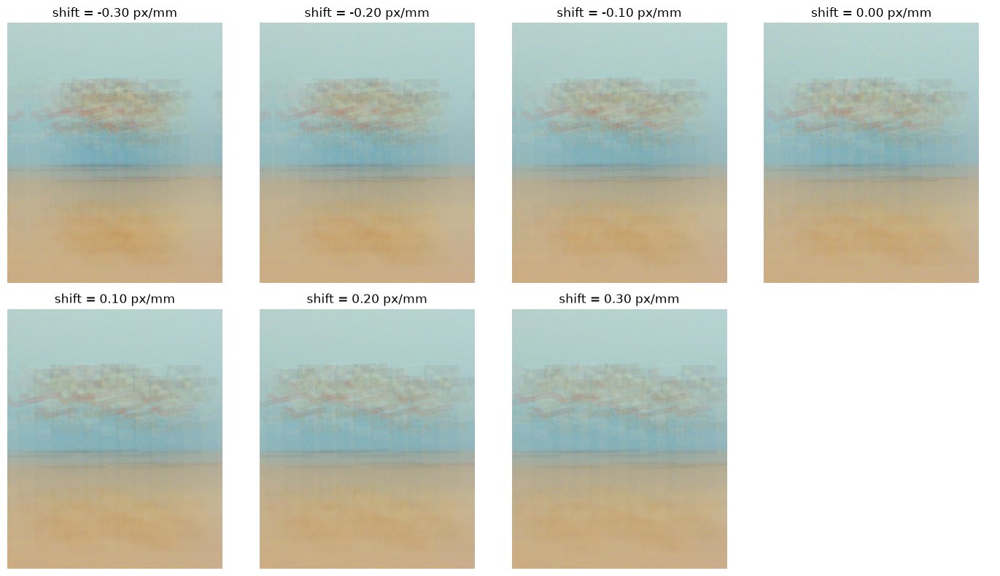

In [17]:
shift_values = [-0.30, -0.20, -0.10, 0.0, 0.10, 0.20, 0.30]

fig, axes = plt.subplots(2, 4, figsize=(14, 8))

for ax, s in zip(axes.ravel(), shift_values):
    refocused = refocus_shift_average(
        cropped_images,
        x_positions,
        shift_per_mm=s
    )

    ax.imshow(refocused)
    ax.set_title(f"shift = {s:.2f} px/mm")
    ax.axis("off")

# hide unused subplot
for ax in axes.ravel()[len(shift_values):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

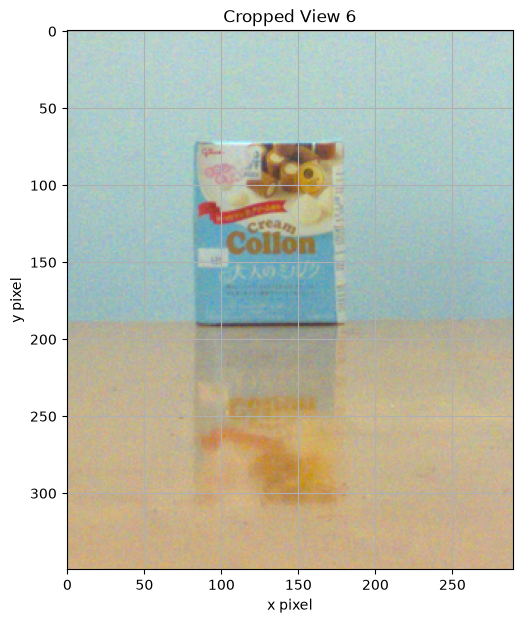

In [18]:
plt.figure(figsize=(7, 7))
plt.imshow(cropped_images[5])   # View 6
plt.title("Cropped View 6")
plt.xlabel("x pixel")
plt.ylabel("y pixel")
plt.grid()
plt.show()

In [19]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Template ROI from View 6
tx1, tx2 = 80, 180
ty1, ty2 = 70, 190

template_rgb = cropped_images[5][ty1:ty2, tx1:tx2]
template_gray = cv2.cvtColor(template_rgb, cv2.COLOR_RGB2GRAY)

match_results = []

for i, img in enumerate(cropped_images):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    result = cv2.matchTemplate(
        gray,
        template_gray,
        cv2.TM_CCOEFF_NORMED
    )

    _, max_val, _, max_loc = cv2.minMaxLoc(result)

    x_match, y_match = max_loc

    match_results.append({
        "view": i + 1,
        "camera_x_mm": float(x_positions[i]),
        "object_x_px": x_match,
        "object_y_px": y_match,
        "match_score": max_val
    })

match_df = pd.DataFrame(match_results)
display(match_df)

,view,camera_x_mm,object_x_px,object_y_px,match_score
0,1,0.0,180,88,0.955041
1,2,20.0,160,72,0.974249
2,3,40.0,139,92,0.963861
3,4,60.0,119,87,0.971071
4,5,80.0,99,77,0.974617
5,6,100.0,80,70,0.999991
6,7,120.0,60,72,0.969911
7,8,140.0,38,92,0.976448
8,9,160.0,18,72,0.962839
9,10,180.0,0,77,0.814725


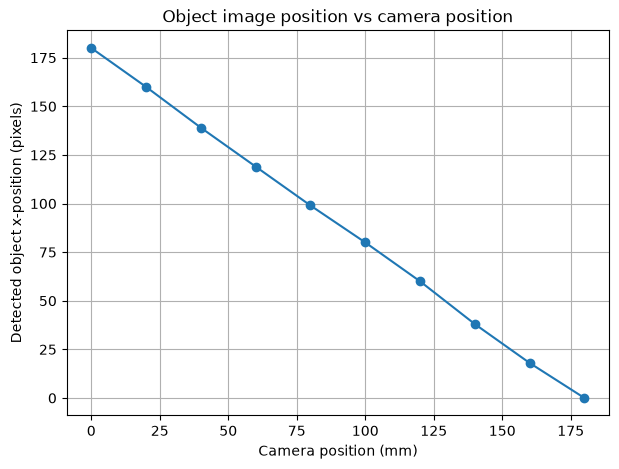

In [20]:
plt.figure(figsize=(7, 5))
plt.plot(
    match_df["camera_x_mm"],
    match_df["object_x_px"],
    "o-"
)

plt.xlabel("Camera position (mm)")
plt.ylabel("Detected object x-position (pixels)")
plt.title("Object image position vs camera position")
plt.grid()
plt.show()

In [21]:
# Linear fit: object image position vs camera position
slope, intercept = np.polyfit(
    match_df["camera_x_mm"],
    match_df["object_x_px"],
    1
)

predicted = slope * match_df["camera_x_mm"] + intercept

ss_res = np.sum((match_df["object_x_px"] - predicted) ** 2)
ss_tot = np.sum(
    (match_df["object_x_px"] - match_df["object_x_px"].mean()) ** 2
)
r2 = 1 - ss_res / ss_tot

print(f"Measured disparity slope = {slope:.4f} px/mm")
print(f"Intercept = {intercept:.2f} px")
print(f"R² = {r2:.6f}")

Measured disparity slope = -1.0045 px/mm
Intercept = 179.71 px
R² = 0.999837


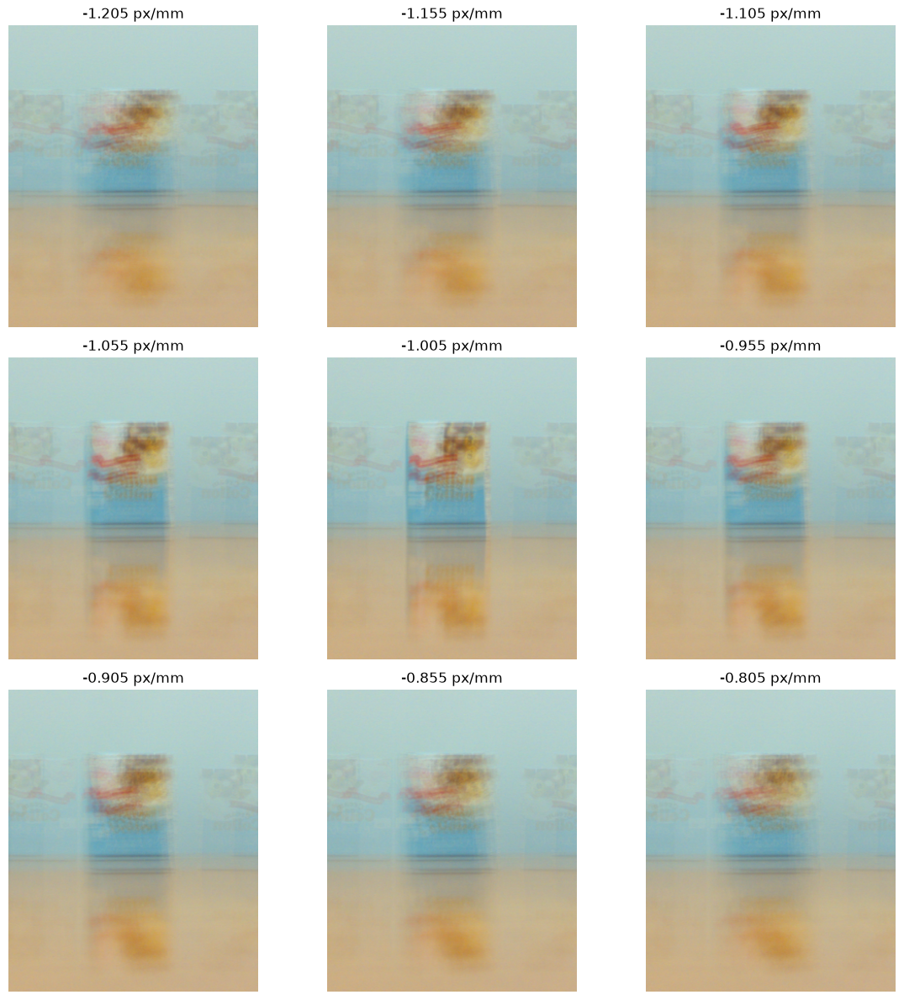

In [22]:
shift_values = np.linspace(
    slope - 0.20,
    slope + 0.20,
    9
)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, s in zip(axes.ravel(), shift_values):
    refocused = refocus_shift_average(
        cropped_images,
        x_positions,
        shift_per_mm=s
    )

    ax.imshow(refocused)
    ax.set_title(f"{s:.3f} px/mm")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
def refocus_shift_average_valid(images, x_positions, shift_per_mm):
    """
    Shift-and-average refocusing without reflected-border artefacts.
    Only valid pixels from each shifted view are averaged.
    """
    h, w, c = images[0].shape

    accumulator = np.zeros((h, w, c), dtype=np.float32)
    weight = np.zeros((h, w), dtype=np.float32)

    x_center = np.mean(x_positions)

    for img, x in zip(images, x_positions):

        shift_x = -shift_per_mm * (x - x_center)

        M = np.float32([
            [1, 0, shift_x],
            [0, 1, 0]
        ])

        # Shift actual image
        shifted = cv2.warpAffine(
            img.astype(np.float32),
            M,
            (w, h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=0
        )

        # Shift a validity mask in exactly the same way
        valid = np.ones((h, w), dtype=np.float32)

        shifted_valid = cv2.warpAffine(
            valid,
            M,
            (w, h),
            flags=cv2.INTER_NEAREST,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=0
        )

        accumulator += shifted * shifted_valid[..., None]
        weight += shifted_valid

    refocused = accumulator / np.maximum(weight[..., None], 1e-6)

    return np.clip(refocused, 0, 255).astype(np.uint8)

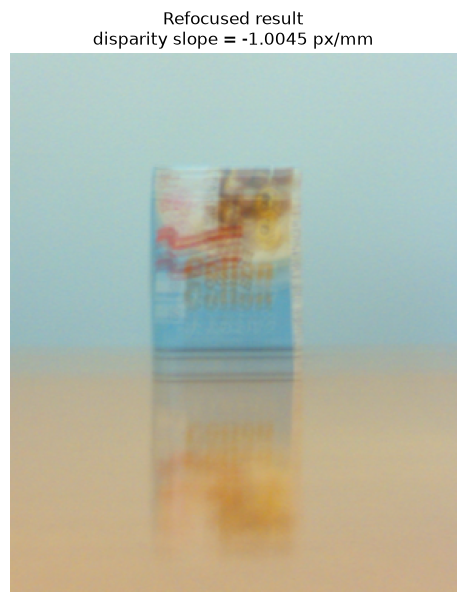

In [24]:
best_slope = slope

refocused_full = refocus_shift_average_valid(
    images,
    x_positions,
    best_slope
)

# Crop AFTER refocusing
refocused_crop = refocused_full[y1:y2, x1:x2]

plt.figure(figsize=(7, 7))
plt.imshow(refocused_crop)
plt.title(
    f"Refocused result\n"
    f"disparity slope = {best_slope:.4f} px/mm"
)
plt.axis("off")
plt.show()

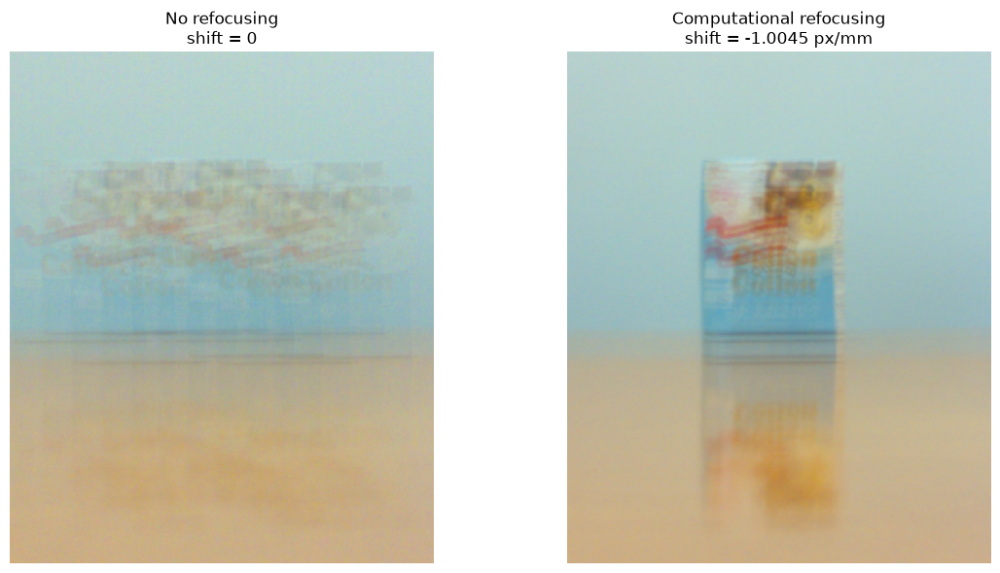

In [25]:
# Simple average without refocusing
average_no_refocus = np.mean(
    np.stack(images).astype(np.float32),
    axis=0
).astype(np.uint8)

average_crop = average_no_refocus[y1:y2, x1:x2]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(average_crop)
axes[0].set_title("No refocusing\nshift = 0")
axes[0].axis("off")

axes[1].imshow(refocused_crop)
axes[1].set_title(
    f"Computational refocusing\n"
    f"shift = {best_slope:.4f} px/mm"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [26]:
def sharpness_laplacian(rgb_img):
    gray = cv2.cvtColor(rgb_img, cv2.COLOR_RGB2GRAY)
    return cv2.Laplacian(gray, cv2.CV_64F).var()

# ROI around the box in the refocused crop
roi_x1, roi_x2 = 75, 185
roi_y1, roi_y2 = 65, 195

slope_scan = np.linspace(-1.30, -0.70, 61)

sharpness_values = []

for s in slope_scan:
    refocused_full = refocus_shift_average_valid(
        images,
        x_positions,
        s
    )

    refocused_crop = refocused_full[y1:y2, x1:x2]
    roi = refocused_crop[roi_y1:roi_y2, roi_x1:roi_x2]

    score = sharpness_laplacian(roi)
    sharpness_values.append(score)

sharpness_values = np.array(sharpness_values)

best_idx = np.argmax(sharpness_values)
best_sharp_slope = slope_scan[best_idx]

print(f"Best sharpness slope = {best_sharp_slope:.4f} px/mm")
print(f"Measured disparity slope = {slope:.4f} px/mm")

Best sharpness slope = -1.0000 px/mm
Measured disparity slope = -1.0045 px/mm


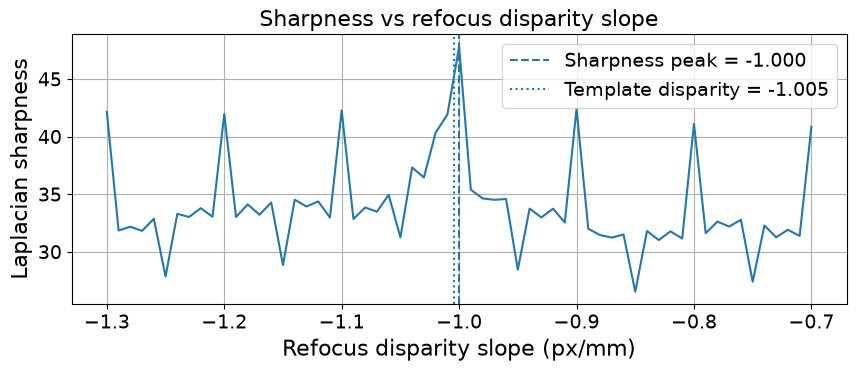

In [121]:
plt.rcParams.update({
    'font.size': 12,          # 全局默认字体大小（影响普通文本、注释等）
    'axes.titlesize': 16,     # 子图标题 (ax.set_title / plt.title)
    'axes.labelsize': 16,     # X/Y 轴标签 (ax.set_xlabel / plt.xlabel)
    'xtick.labelsize': 14,    # X 轴刻度数字
    'ytick.labelsize': 14,    # Y 轴刻度数字
    'legend.fontsize': 14,    # 图例文字 (plt.legend)
    'legend.title_fontsize': 14, # 图例标题
    'figure.titlesize': 18    # 整张画布总标题 (fig.suptitle)
})

plt.figure(figsize=(10, 3.5))

plt.plot(slope_scan, sharpness_values)
plt.axvline(
    best_sharp_slope,
    linestyle="--",
    label=f"Sharpness peak = {best_sharp_slope:.3f}"
)
plt.axvline(
    slope,
    linestyle=":",
    label=f"Template disparity = {slope:.3f}"
)

plt.xlabel("Refocus disparity slope (px/mm)")
plt.ylabel("Laplacian sharpness")
plt.title("Sharpness vs refocus disparity slope")
plt.grid()
plt.legend()
plt.show()

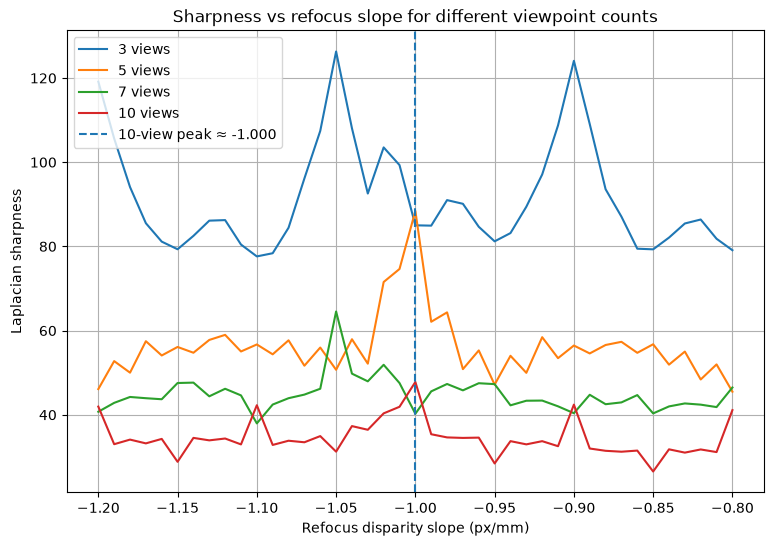

,n_views,indices_used,best_slope_px_per_mm,max_sharpness
0,3,"[0, 4, 9]",-1.05,126.299558
1,5,"[0, 2, 4, 7, 9]",-1.00,88.437408
2,7,"[0, 2, 3, 4, 6, 8, 9]",-1.05,64.539520
3,10,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",-1.00,47.796489


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def pick_evenly_spaced_indices(n_total, n_keep):
    idx = np.linspace(0, n_total - 1, n_keep)
    idx = np.round(idx).astype(int)
    idx = np.unique(idx)

    # 如果因为 round 导致数量不够，就补齐
    while len(idx) < n_keep:
        candidates = [i for i in range(n_total) if i not in idx]
        best = max(candidates, key=lambda c: min(abs(c - s) for s in idx))
        idx = np.sort(np.append(idx, best))

    return idx

view_counts = [3, 5, 7, 10]
slope_scan_counts = np.linspace(best_sharp_slope - 0.20, best_sharp_slope + 0.20, 41)

results_counts = []

plt.figure(figsize=(9, 6))

for n_keep in view_counts:
    idx = pick_evenly_spaced_indices(len(images), n_keep)

    images_sub = [images[i] for i in idx]
    x_sub = [x_positions[i] for i in idx]

    sharp_curve = []

    for s in slope_scan_counts:
        refocused_full = refocus_shift_average_valid(images_sub, x_sub, s)
        refocused_crop = refocused_full[y1:y2, x1:x2]
        roi = refocused_crop[roi_y1:roi_y2, roi_x1:roi_x2]
        score = sharpness_laplacian(roi)
        sharp_curve.append(score)

    sharp_curve = np.array(sharp_curve)
    best_i = np.argmax(sharp_curve)
    best_s = slope_scan_counts[best_i]
    best_score = sharp_curve[best_i]

    results_counts.append({
        "n_views": n_keep,
        "indices_used": idx.tolist(),
        "best_slope_px_per_mm": float(best_s),
        "max_sharpness": float(best_score)
    })

    plt.plot(slope_scan_counts, sharp_curve, label=f"{n_keep} views")

plt.axvline(best_sharp_slope, linestyle="--", label=f"10-view peak ≈ {best_sharp_slope:.3f}")
plt.xlabel("Refocus disparity slope (px/mm)")
plt.ylabel("Laplacian sharpness")
plt.title("Sharpness vs refocus slope for different viewpoint counts")
plt.grid()
plt.legend()
plt.show()

df_counts = pd.DataFrame(results_counts)
df_counts

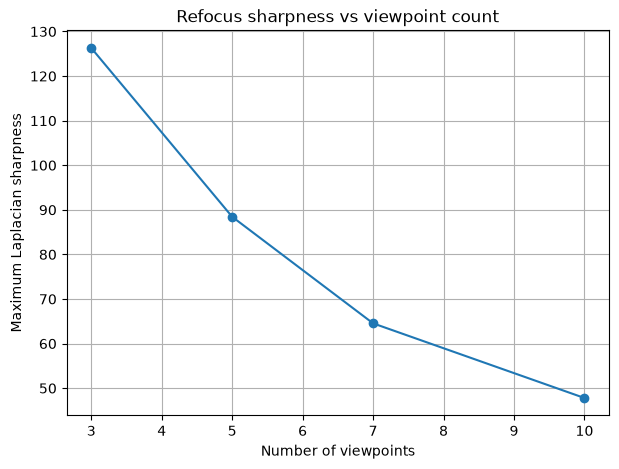

,n_views,indices_used,best_slope_px_per_mm,max_sharpness
0,3,"[0, 4, 9]",-1.05,126.299558
1,5,"[0, 2, 4, 7, 9]",-1.00,88.437408
2,7,"[0, 2, 3, 4, 6, 8, 9]",-1.05,64.539520
3,10,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",-1.00,47.796489


In [29]:
plt.figure(figsize=(7,5))
plt.plot(df_counts["n_views"], df_counts["max_sharpness"], marker="o")
plt.xlabel("Number of viewpoints")
plt.ylabel("Maximum Laplacian sharpness")
plt.title("Refocus sharpness vs viewpoint count")
plt.grid()
plt.show()

df_counts

In [30]:
def tenengrad_sharpness(rgb_img):
    gray = cv2.cvtColor(rgb_img, cv2.COLOR_RGB2GRAY).astype(np.float32)

    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)

    magnitude_sq = gx**2 + gy**2

    return np.mean(magnitude_sq)

In [31]:
fixed_slope = slope   # measured disparity slope = -1.0045 px/mm

results_fixed = []

for n_keep in [3, 5, 7, 10]:

    idx = pick_evenly_spaced_indices(len(images), n_keep)

    images_sub = [images[i] for i in idx]
    x_sub = np.array([x_positions[i] for i in idx], dtype=np.float32)

    refocused = refocus_shift_average_valid(
        images_sub,
        x_sub,
        fixed_slope
    )

    crop = refocused[y1:y2, x1:x2]
    roi = crop[roi_y1:roi_y2, roi_x1:roi_x2]

    lap_score = sharpness_laplacian(roi)
    ten_score = tenengrad_sharpness(roi)

    results_fixed.append({
        "n_views": n_keep,
        "indices_used": idx.tolist(),
        "baseline_mm": float(x_sub.max() - x_sub.min()),
        "laplacian": lap_score,
        "tenengrad": ten_score
    })

df_fixed = pd.DataFrame(results_fixed)
df_fixed

,n_views,indices_used,baseline_mm,laplacian,tenengrad
0,3,"[0, 4, 9]",180.0,105.991727,2740.674072
1,5,"[0, 2, 4, 7, 9]",180.0,70.140025,1850.378052
2,7,"[0, 2, 3, 4, 6, 8, 9]",180.0,47.303183,1410.184814
3,10,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",180.0,41.149296,1290.829956


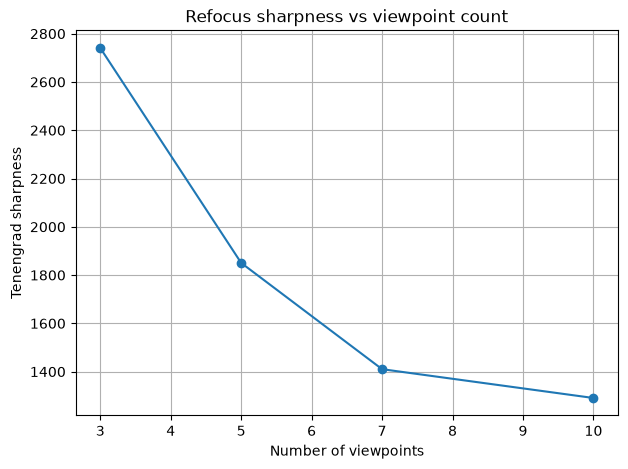

In [32]:
plt.figure(figsize=(7,5))

plt.plot(
    df_fixed["n_views"],
    df_fixed["tenengrad"],
    marker="o"
)

plt.xlabel("Number of viewpoints")
plt.ylabel("Tenengrad sharpness")
plt.title("Refocus sharpness vs viewpoint count")
plt.grid()

plt.show()

In [33]:
# SNR vs viewpoint count

In [34]:
snr_root = SESSIONS / "snr"
snr_low = snr_root / "snr_uniform_low"

df_snr_low = pd.read_csv(snr_low / "manifest.csv")

print("Shape:", df_snr_low.shape)
print("Columns:", list(df_snr_low.columns))

display(
    df_snr_low[
        [
            "position_index",
            "repeat_index",
            "nominal_x_mm",
            "x_mm",
            "filename",
            "exposure_us_requested",
            "gain_requested",
            "scene_condition"
        ]
    ].head(30)
)

Shape: (24, 34)
Columns: ['step_id', 'mode', 'cycle_index', 'position_index', 'repeat_index', 'nominal_x_mm', 'x_mm', 'timestamp_utc', 'filename', 'bytes', 'sha256', 'exposure_us_requested', 'gain_requested', 'ae_requested', 'actual_exposure_us', 'actual_gain', 'frame_duration_us', 'sensor_timestamp_ns', 'capture_metadata_source', 'raw_height', 'raw_width', 'black_levels_dn', 'white_level_dn', 'min_dn', 'median_dn', 'p99_dn', 'max_dn', 'saturated_pct', 'near_black_pct', 'scene_condition', 'reference_kind', 'moved_away_and_returned', 'notes', 'recovered_orphan']


,position_index,repeat_index,nominal_x_mm,x_mm,filename,exposure_us_requested,gain_requested,scene_condition
0,1,1,100.0,100.0,raw/step_001_x+0100.000mm_cycle01_rep001.dng,16000,4.0,textured
1,1,2,100.0,100.0,raw/step_001_x+0100.000mm_cycle01_rep002.dng,16000,4.0,textured
2,1,3,100.0,100.0,raw/step_001_x+0100.000mm_cycle01_rep003.dng,16000,4.0,textured
3,1,4,100.0,100.0,raw/step_001_x+0100.000mm_cycle01_rep004.dng,16000,4.0,textured
4,1,5,100.0,100.0,raw/step_001_x+0100.000mm_cycle01_rep005.dng,16000,4.0,textured
5,1,6,100.0,100.0,raw/step_001_x+0100.000mm_cycle01_rep006.dng,16000,4.0,textured
6,1,7,100.0,100.0,raw/step_001_x+0100.000mm_cycle01_rep007.dng,16000,4.0,textured
7,1,8,100.0,100.0,raw/step_001_x+0100.000mm_cycle01_rep008.dng,16000,4.0,textured
8,1,9,100.0,100.0,raw/step_001_x+0100.000mm_cycle01_rep009.dng,16000,4.0,textured
9,1,10,100.0,100.0,raw/step_001_x+0100.000mm_cycle01_rep010.dng,16000,4.0,textured


In [35]:
print("Positions:", sorted(df_snr_low["x_mm"].dropna().unique()))
print("Repeats per position:")
print(df_snr_low.groupby("x_mm")["repeat_index"].count().to_dict())

print("Exposure values:",
      sorted(df_snr_low["exposure_us_requested"].dropna().unique()))

print("Gain values:",
      sorted(df_snr_low["gain_requested"].dropna().unique()))

print("Scene conditions:",
      df_snr_low["scene_condition"].dropna().unique())

Positions: [np.float64(100.0)]
Repeats per position:
{100.0: 24}
Exposure values: [np.int64(16000)]
Gain values: [np.float64(4.0)]
Scene conditions: <ArrowStringArray>
['textured']
Length: 1, dtype: str


In [36]:
snr_sessions = [
    "snr_dark",
    "snr_textured",
    "snr_uniform_low",
    "snr_uniform_mid",
    "snr_uniform_high"
]

snr_summary = []

for name in snr_sessions:
    df = pd.read_csv(snr_root / name / "manifest.csv")

    snr_summary.append({
        "session": name,
        "n_frames": len(df),
        "positions_mm": sorted(df["x_mm"].dropna().unique().tolist()),
        "exposure_us": sorted(df["exposure_us_requested"].dropna().unique().tolist()),
        "gain": sorted(df["gain_requested"].dropna().unique().tolist()),
        "scene_condition": list(df["scene_condition"].dropna().unique()),
        "reference_kind": list(df["reference_kind"].dropna().unique()),
        "median_dn_mean": df["median_dn"].mean(),
        "p99_dn_mean": df["p99_dn"].mean(),
        "near_black_pct_mean": df["near_black_pct"].mean()
    })

df_snr_summary = pd.DataFrame(snr_summary)
display(df_snr_summary)

,session,n_frames,positions_mm,exposure_us,gain,scene_condition,reference_kind,median_dn_mean,p99_dn_mean,near_black_pct_mean
0,snr_dark,24,[100.0],[32000],[4.0],[textured],[],15.000000,19.000000,99.831923
1,snr_textured,24,[100.0],[32000],[4.0],[textured],[],426.708333,748.250000,0.000016
2,snr_uniform_low,24,[100.0],[16000],[4.0],[textured],[],260.791667,326.583333,0.000000
3,snr_uniform_mid,24,[100.0],[24000],[4.0],[textured],[],384.750000,474.541667,0.000000
4,snr_uniform_high,24,[100.0],[32000],[4.0],[textured],[],509.291667,621.208333,0.000000


In [37]:
for name in snr_sessions:
    df = pd.read_csv(snr_root / name / "manifest.csv")

    print("\n" + "=" * 70)
    print(name)

    print("Notes:")
    print(df["notes"].dropna().unique())

    print("Reference kind:")
    print(df["reference_kind"].dropna().unique())

    print("Scene condition:")
    print(df["scene_condition"].dropna().unique())


snr_dark
Notes:
[]
Reference kind:
[]
Scene condition:
<ArrowStringArray>
['textured']
Length: 1, dtype: str

snr_textured
Notes:
[]
Reference kind:
[]
Scene condition:
<ArrowStringArray>
['textured']
Length: 1, dtype: str

snr_uniform_low
Notes:
[]
Reference kind:
[]
Scene condition:
<ArrowStringArray>
['textured']
Length: 1, dtype: str

snr_uniform_mid
Notes:
[]
Reference kind:
[]
Scene condition:
<ArrowStringArray>
['textured']
Length: 1, dtype: str

snr_uniform_high
Notes:
[]
Reference kind:
[]
Scene condition:
<ArrowStringArray>
['textured']
Length: 1, dtype: str


In [38]:
try:
    import rawpy
    print("rawpy is installed")
except ImportError:
    print("rawpy is NOT installed")

rawpy is installed


In [39]:
from pathlib import Path

low_dng_files = sorted(snr_low.rglob("*.dng"))

print("Number of DNG files:", len(low_dng_files))

for f in low_dng_files[:5]:
    print(f.relative_to(snr_low))

Number of DNG files: 24
raw\step_001_x+0100.000mm_cycle01_rep001.dng
raw\step_001_x+0100.000mm_cycle01_rep002.dng
raw\step_001_x+0100.000mm_cycle01_rep003.dng
raw\step_001_x+0100.000mm_cycle01_rep004.dng
raw\step_001_x+0100.000mm_cycle01_rep005.dng


RAW shape: (1080, 1920)
Min: 113.0
Median: 260.0
Max: 391.0


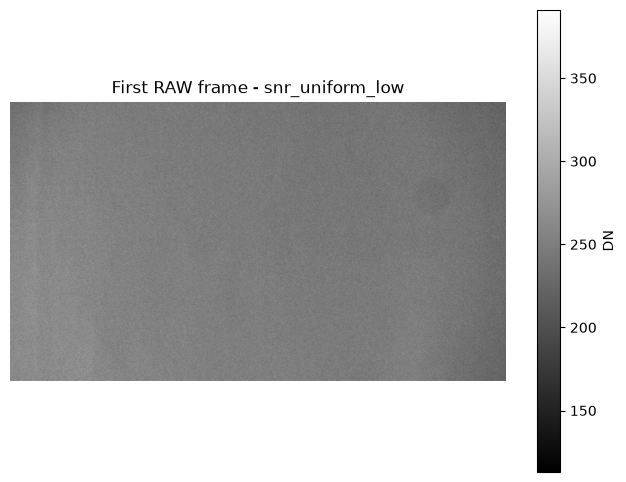

In [40]:
import rawpy
import numpy as np
import matplotlib.pyplot as plt

with rawpy.imread(str(low_dng_files[0])) as raw:
    raw_img = raw.raw_image_visible.copy().astype(np.float32)

print("RAW shape:", raw_img.shape)
print("Min:", raw_img.min())
print("Median:", np.median(raw_img))
print("Max:", raw_img.max())

plt.figure(figsize=(8, 6))
plt.imshow(raw_img, cmap="gray")
plt.title("First RAW frame - snr_uniform_low")
plt.colorbar(label="DN")
plt.axis("off")
plt.show()

In [41]:
def load_raw_stack(folder):
    files = sorted(folder.rglob("*.dng"))

    stack = []

    for f in files:
        with rawpy.imread(str(f)) as raw:
            img = raw.raw_image_visible.copy().astype(np.float32)
            stack.append(img)

    return np.stack(stack, axis=0)

low_stack = load_raw_stack(snr_low)

print("Stack shape:", low_stack.shape)

Stack shape: (24, 1080, 1920)


In [42]:
low_mean = np.mean(low_stack, axis=0)
low_std  = np.std(low_stack, axis=0, ddof=1)

print("Mean image median DN:", np.median(low_mean))
print("Temporal noise median DN:", np.median(low_std))

Mean image median DN: 261.20834
Temporal noise median DN: 14.239159


In [43]:
h, w = low_mean.shape

roi_half_h = 150
roi_half_w = 250

cy = h // 2
cx = w // 2

y1_snr = cy - roi_half_h
y2_snr = cy + roi_half_h
x1_snr = cx - roi_half_w
x2_snr = cx + roi_half_w

low_mean_roi = low_mean[y1_snr:y2_snr, x1_snr:x2_snr]
low_std_roi  = low_std[y1_snr:y2_snr, x1_snr:x2_snr]

print("ROI mean signal:", np.mean(low_mean_roi))
print("ROI temporal noise std:", np.mean(low_std_roi))

ROI mean signal: 247.86682
ROI temporal noise std: 14.311314


In [44]:
snr_dark = snr_root / "snr_dark"

dark_stack = load_raw_stack(snr_dark)

print("Dark stack shape:", dark_stack.shape)

dark_mean = np.mean(dark_stack, axis=0)
dark_std  = np.std(dark_stack, axis=0, ddof=1)

dark_mean_roi = dark_mean[y1_snr:y2_snr, x1_snr:x2_snr]
dark_std_roi  = dark_std[y1_snr:y2_snr, x1_snr:x2_snr]

print("Dark ROI mean DN:", np.mean(dark_mean_roi))
print("Dark temporal noise std:", np.mean(dark_std_roi))

Dark stack shape: (24, 1080, 1920)
Dark ROI mean DN: 15.181655
Dark temporal noise std: 1.387203


In [45]:
signal_low = np.mean(low_mean_roi) - np.mean(dark_mean_roi)

noise_low = np.mean(low_std_roi)

snr_low_linear = signal_low / noise_low
snr_low_db = 20 * np.log10(snr_low_linear)

print(f"Dark-corrected signal: {signal_low:.3f} DN")
print(f"Temporal noise: {noise_low:.3f} DN")
print(f"SNR: {snr_low_linear:.3f}")
print(f"SNR: {snr_low_db:.3f} dB")

Dark-corrected signal: 232.685 DN
Temporal noise: 14.311 DN
SNR: 16.259
SNR: 24.222 dB


In [46]:
snr_conditions = {
    "low": snr_root / "snr_uniform_low",
    "mid": snr_root / "snr_uniform_mid",
    "high": snr_root / "snr_uniform_high"
}

snr_results = []

dark_level = np.mean(dark_mean_roi)

for name, folder in snr_conditions.items():
    stack = load_raw_stack(folder)

    mean_img = np.mean(stack, axis=0)
    std_img  = np.std(stack, axis=0, ddof=1)

    mean_roi = mean_img[y1_snr:y2_snr, x1_snr:x2_snr]
    std_roi  = std_img[y1_snr:y2_snr, x1_snr:x2_snr]

    signal = np.mean(mean_roi) - dark_level
    noise = np.mean(std_roi)

    snr_linear = signal / noise
    snr_db = 20 * np.log10(snr_linear)

    df = pd.read_csv(folder / "manifest.csv")
    exposure_us = df["exposure_us_requested"].dropna().iloc[0]

    snr_results.append({
        "condition": name,
        "exposure_ms": exposure_us / 1000,
        "signal_DN": signal,
        "noise_DN": noise,
        "SNR_linear": snr_linear,
        "SNR_dB": snr_db
    })

df_snr = pd.DataFrame(snr_results)

display(df_snr)

,condition,exposure_ms,signal_DN,noise_DN,SNR_linear,SNR_dB
0,low,16.0,232.685165,14.311314,16.258827,24.221785
1,mid,24.0,349.517456,17.325701,20.173351,26.095562
2,high,32.0,466.781067,19.828810,23.540548,27.436331


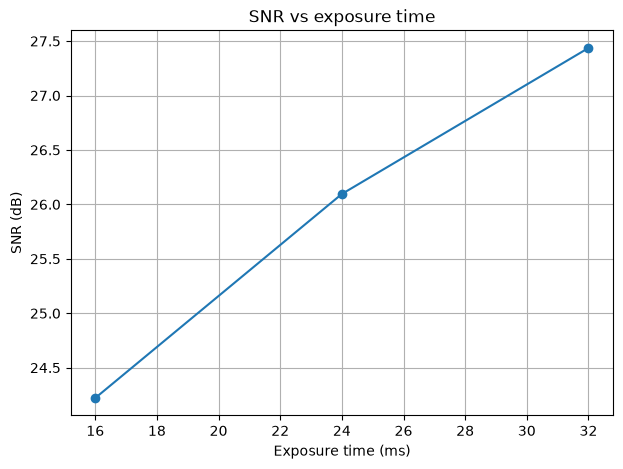

In [47]:
plt.figure(figsize=(7, 5))

plt.plot(
    df_snr["exposure_ms"],
    df_snr["SNR_dB"],
    marker="o"
)

plt.xlabel("Exposure time (ms)")
plt.ylabel("SNR (dB)")
plt.title("SNR vs exposure time")
plt.grid()

plt.show()

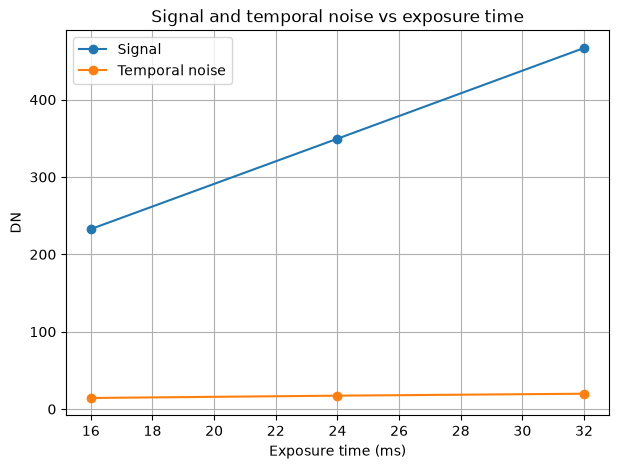

In [48]:
plt.figure(figsize=(7, 5))

plt.plot(
    df_snr["exposure_ms"],
    df_snr["signal_DN"],
    marker="o",
    label="Signal"
)

plt.plot(
    df_snr["exposure_ms"],
    df_snr["noise_DN"],
    marker="o",
    label="Temporal noise"
)

plt.xlabel("Exposure time (ms)")
plt.ylabel("DN")
plt.title("Signal and temporal noise vs exposure time")
plt.grid()
plt.legend()

plt.show()

In [49]:
train_path = lightfield_root / "lf_train_01"
train_manifest = pd.read_csv(train_path / "manifest.csv")

# Sort by camera position and repeat
train_manifest = train_manifest.sort_values(
    ["position_index", "repeat_index"]
).reset_index(drop=True)

display(
    train_manifest[
        ["position_index", "repeat_index", "x_mm", "filename"]
    ].head(10)
)

,position_index,repeat_index,x_mm,filename
0,1,1,0.0,raw/step_001_x+0000.000mm_cycle01_rep001.dng
1,1,2,0.0,raw/step_001_x+0000.000mm_cycle01_rep002.dng
2,1,3,0.0,raw/step_001_x+0000.000mm_cycle01_rep003.dng
3,2,1,20.0,raw/step_002_x+0020.000mm_cycle01_rep001.dng
4,2,2,20.0,raw/step_002_x+0020.000mm_cycle01_rep002.dng
5,2,3,20.0,raw/step_002_x+0020.000mm_cycle01_rep003.dng
6,3,1,40.0,raw/step_003_x+0040.000mm_cycle01_rep001.dng
7,3,2,40.0,raw/step_003_x+0040.000mm_cycle01_rep002.dng
8,3,3,40.0,raw/step_003_x+0040.000mm_cycle01_rep003.dng
9,4,1,60.0,raw/step_004_x+0060.000mm_cycle01_rep001.dng


In [50]:
# First RAW file
first_raw_path = train_path / train_manifest.iloc[0]["filename"]

with rawpy.imread(str(first_raw_path)) as raw:
    print("RAW visible shape:", raw.raw_image_visible.shape)
    print("Orientation/flip code:", raw.sizes.flip)

    rgb16 = raw.postprocess(
        use_camera_wb=True,
        no_auto_bright=True,
        output_bps=16,
        gamma=(1, 1)
    )

print("Processed RGB shape:", rgb16.shape)
print("dtype:", rgb16.dtype)
print("min/max:", rgb16.min(), rgb16.max())

RAW visible shape: (1080, 1920)
Orientation/flip code: 0
Processed RGB shape: (1080, 1920, 3)
dtype: uint16
min/max: 0 65535


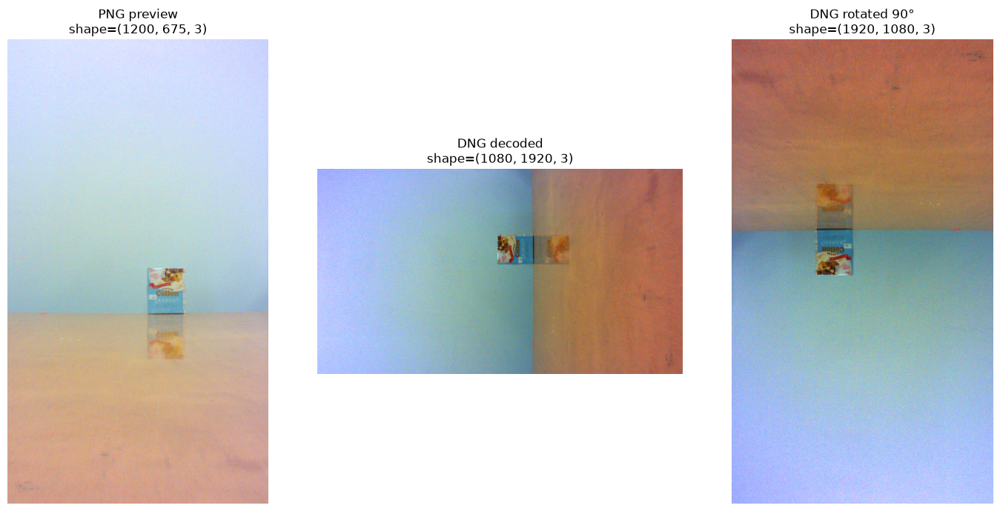

In [51]:
# Corresponding preview at x = 0 mm
preview0 = np.array(Image.open(png_files[0]).convert("RGB"))

fig, axes = plt.subplots(1, 3, figsize=(15, 7))

axes[0].imshow(preview0)
axes[0].set_title(f"PNG preview\nshape={preview0.shape}")
axes[0].axis("off")

axes[1].imshow(rgb16 / 65535.0)
axes[1].set_title(f"DNG decoded\nshape={rgb16.shape}")
axes[1].axis("off")

# Try one 90-degree rotation for comparison
rgb16_rot = np.rot90(rgb16)

axes[2].imshow(rgb16_rot / 65535.0)
axes[2].set_title(f"DNG rotated 90°\nshape={rgb16_rot.shape}")
axes[2].axis("off")

plt.tight_layout()
plt.show()

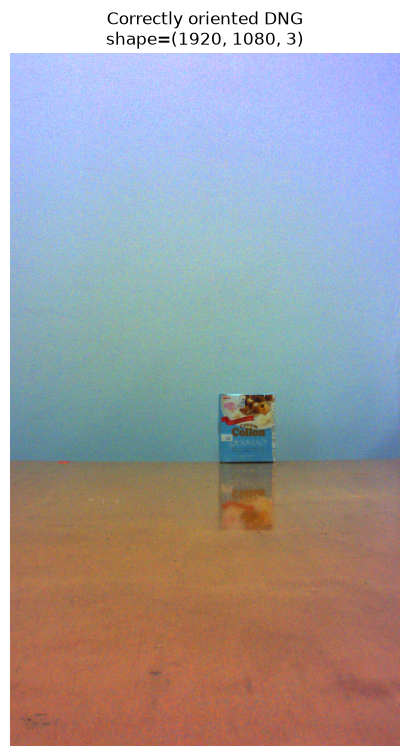

Correct shape: (1920, 1080, 3)


In [52]:
rgb16_correct = np.rot90(rgb16, k=3)

plt.figure(figsize=(6, 9))
plt.imshow(rgb16_correct / 65535.0)
plt.title(f"Correctly oriented DNG\nshape={rgb16_correct.shape}")
plt.axis("off")
plt.show()

print("Correct shape:", rgb16_correct.shape)

In [53]:
def load_lightfield_rgb16(path):
    with rawpy.imread(str(path)) as raw:
        rgb = raw.postprocess(
            use_camera_wb=True,
            no_auto_bright=True,
            output_bps=16,
            gamma=(1, 1)
        )

    # Camera RAW is landscape; rotate clockwise to match PNG previews
    rgb = np.rot90(rgb, k=3)

    return rgb.astype(np.float32)

In [54]:
raw_sets = {}

for rep in [1, 2, 3]:

    df_rep = train_manifest[
        train_manifest["repeat_index"] == rep
    ].sort_values("position_index")

    imgs_rep = []

    for _, row in df_rep.iterrows():
        path = train_path / row["filename"]
        img = load_lightfield_rgb16(path)
        imgs_rep.append(img)

    raw_sets[rep] = imgs_rep

    print(
        f"Repeat {rep}: "
        f"{len(imgs_rep)} views, "
        f"shape={imgs_rep[0].shape}"
    )

Repeat 1: 10 views, shape=(1920, 1080, 3)
Repeat 2: 10 views, shape=(1920, 1080, 3)
Repeat 3: 10 views, shape=(1920, 1080, 3)


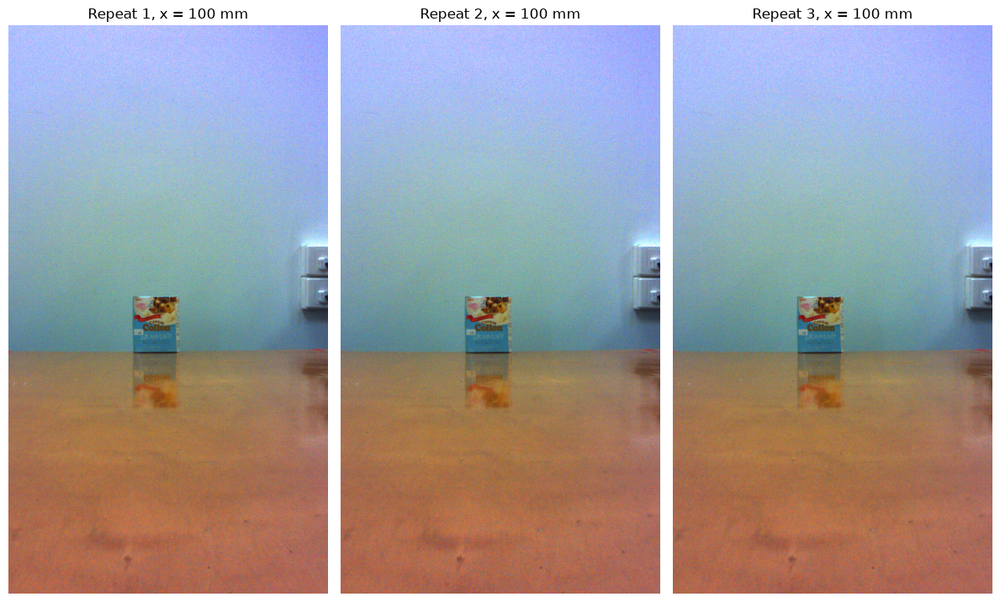

In [55]:
# Show centre viewpoint (100 mm) from all three repeats

fig, axes = plt.subplots(1, 3, figsize=(12, 8))

for rep, ax in zip([1, 2, 3], axes):
    img = raw_sets[rep][5]

    ax.imshow(np.clip(img / 65535.0, 0, 1))
    ax.set_title(f"Repeat {rep}, x = 100 mm")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [56]:
png_width = images[0].shape[1]       # 675
raw_width = raw_sets[1][0].shape[1]  # 1080

scale_factor = raw_width / png_width

raw_slope = slope * scale_factor

print(f"PNG width = {png_width}")
print(f"RAW oriented width = {raw_width}")
print(f"Scale factor = {scale_factor:.4f}")
print(f"PNG disparity slope = {slope:.4f} px/mm")
print(f"RAW disparity slope = {raw_slope:.4f} px/mm")

PNG width = 675
RAW oriented width = 1080
Scale factor = 1.6000
PNG disparity slope = -1.0045 px/mm
RAW disparity slope = -1.6073 px/mm


In [57]:
def refocus_float_valid(images, x_positions, shift_per_mm):
    """
    Refocus linear float images without clipping to uint8.
    Valid pixels only; no reflected-border artefacts.
    """
    h, w, c = images[0].shape

    accumulator = np.zeros((h, w, c), dtype=np.float32)
    weight = np.zeros((h, w), dtype=np.float32)

    x_positions = np.asarray(x_positions, dtype=np.float32)
    x_center = np.mean(x_positions)

    for img, x in zip(images, x_positions):

        shift_x = -shift_per_mm * (x - x_center)

        M = np.float32([
            [1, 0, shift_x],
            [0, 1, 0]
        ])

        shifted = cv2.warpAffine(
            img.astype(np.float32),
            M,
            (w, h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=0
        )

        valid = np.ones((h, w), dtype=np.float32)

        shifted_valid = cv2.warpAffine(
            valid,
            M,
            (w, h),
            flags=cv2.INTER_NEAREST,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=0
        )

        accumulator += shifted * shifted_valid[..., None]
        weight += shifted_valid

    return accumulator / np.maximum(weight[..., None], 1e-6)

RAW target ROI: 408 584 904 1112


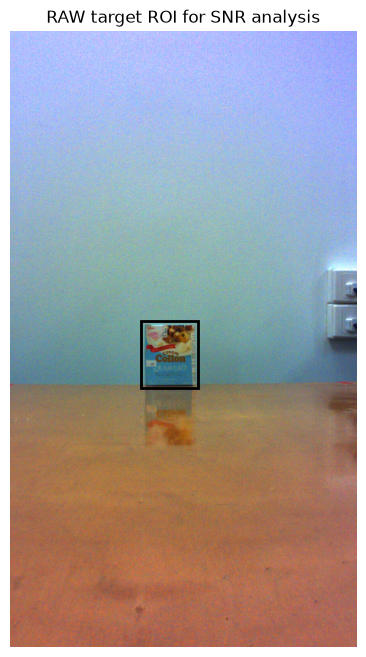

In [58]:
# ROI around the target object in the full oriented RAW image
raw_roi_x1 = int((x1 + roi_x1) * scale_factor)
raw_roi_x2 = int((x1 + roi_x2) * scale_factor)

raw_roi_y1 = int((y1 + roi_y1) * scale_factor)
raw_roi_y2 = int((y1 + roi_y2) * scale_factor)

print(
    "RAW target ROI:",
    raw_roi_x1, raw_roi_x2,
    raw_roi_y1, raw_roi_y2
)

# Check visually
check_img = raw_sets[1][5]

plt.figure(figsize=(6, 8))
plt.imshow(np.clip(check_img / 65535.0, 0, 1))

rect = plt.Rectangle(
    (raw_roi_x1, raw_roi_y1),
    raw_roi_x2 - raw_roi_x1,
    raw_roi_y2 - raw_roi_y1,
    fill=False,
    linewidth=2
)

plt.gca().add_patch(rect)
plt.title("RAW target ROI for SNR analysis")
plt.axis("off")
plt.show()

In [59]:
def rgb_to_linear_gray(rgb):
    """
    Linear luminance approximation from linear RGB.
    """
    return (
        0.2126 * rgb[..., 0] +
        0.7152 * rgb[..., 1] +
        0.0722 * rgb[..., 2]
    )

In [60]:
dark_folder = snr_root / "snr_dark"
dark_files = sorted(dark_folder.rglob("*.dng"))

dark_roi_means = []

for f in dark_files:
    dark_rgb = load_lightfield_rgb16(f)

    dark_roi = dark_rgb[
        raw_roi_y1:raw_roi_y2,
        raw_roi_x1:raw_roi_x2
    ]

    dark_gray = rgb_to_linear_gray(dark_roi)

    dark_roi_means.append(np.mean(dark_gray))

dark_level_linear = np.mean(dark_roi_means)

print(f"Number of dark frames = {len(dark_files)}")
print(f"Processed dark level = {dark_level_linear:.3f}")

Number of dark frames = 24
Processed dark level = 25.345


In [61]:
view_count_indices = {
    1:  [5],                       # x = 100 mm, input view
    3:  [0, 4, 9],                 # approximately full baseline
    5:  [0, 2, 4, 7, 9],
    7:  [0, 2, 3, 4, 6, 8, 9],
    10: list(range(10))
}

snr_view_results = []

for n_views, idx in view_count_indices.items():

    repeat_rois = []

    for rep in [1, 2, 3]:

        selected_images = [raw_sets[rep][i] for i in idx]
        selected_x = np.array([x_positions[i] for i in idx],
                              dtype=np.float32)

        if n_views == 1:
            # Single input image: no refocusing
            output = selected_images[0]

        else:
            output = refocus_float_valid(
                selected_images,
                selected_x,
                raw_slope
            )

        roi_rgb = output[
            raw_roi_y1:raw_roi_y2,
            raw_roi_x1:raw_roi_x2
        ]

        roi_gray = rgb_to_linear_gray(roi_rgb)

        repeat_rois.append(roi_gray)

    # 3 independent outputs
    repeat_stack = np.stack(repeat_rois, axis=0)

    temporal_mean = np.mean(repeat_stack, axis=0)
    temporal_std = np.std(repeat_stack, axis=0, ddof=1)

    signal = np.mean(temporal_mean) - dark_level_linear
    noise = np.mean(temporal_std)

    snr_linear = signal / noise
    snr_db = 20 * np.log10(snr_linear)

    baseline = (
        float(max(x_positions[i] for i in idx) -
              min(x_positions[i] for i in idx))
        if n_views > 1 else 0.0
    )

    snr_view_results.append({
        "n_views": n_views,
        "indices_used": idx,
        "baseline_mm": baseline,
        "signal": signal,
        "temporal_noise": noise,
        "SNR_linear": snr_linear,
        "SNR_dB": snr_db
    })

df_snr_views = pd.DataFrame(snr_view_results)

display(df_snr_views)

,n_views,indices_used,baseline_mm,signal,temporal_noise,SNR_linear,SNR_dB
0,1,[5],0.0,27656.093750,1222.795166,22.617111,27.088741
1,3,"[0, 4, 9]",180.0,29708.712891,625.240479,47.515659,33.536736
2,5,"[0, 2, 4, 7, 9]",180.0,30050.876953,543.315247,55.310204,34.856106
3,7,"[0, 2, 3, 4, 6, 8, 9]",180.0,29347.677734,441.446930,66.480644,36.453903
4,10,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",180.0,29034.539062,360.062988,80.637390,38.130730


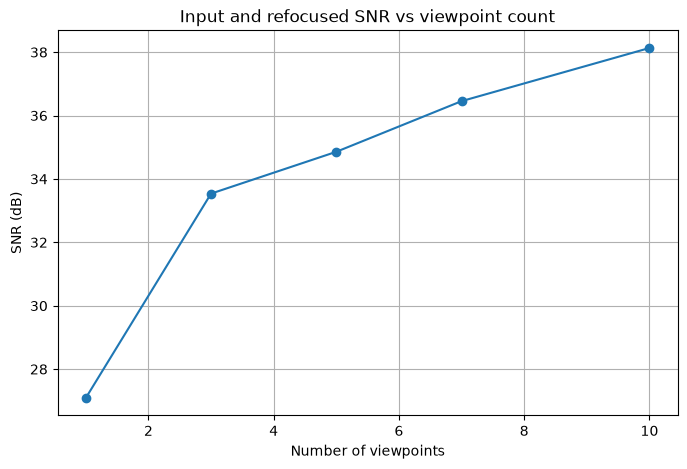

In [62]:
plt.figure(figsize=(8, 5))

plt.plot(
    df_snr_views["n_views"],
    df_snr_views["SNR_dB"],
    marker="o"
)

plt.xlabel("Number of viewpoints")
plt.ylabel("SNR (dB)")
plt.title("Input and refocused SNR vs viewpoint count")
plt.grid()

plt.show()

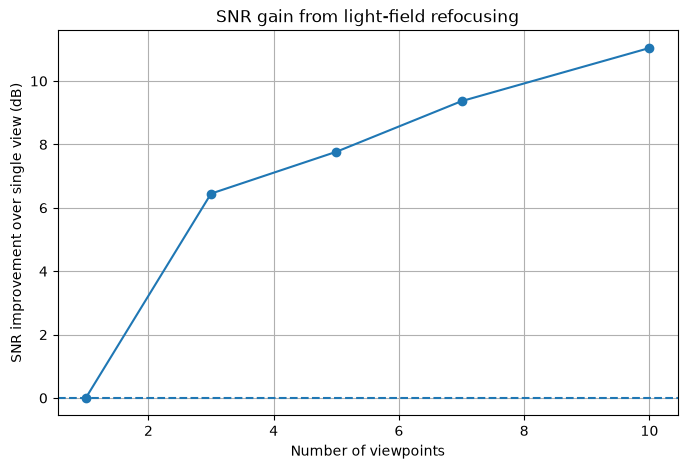

,n_views,indices_used,baseline_mm,signal,temporal_noise,SNR_linear,SNR_dB,SNR_improvement_dB
0,1,[5],0.0,27656.093750,1222.795166,22.617111,27.088741,0.000000
1,3,"[0, 4, 9]",180.0,29708.712891,625.240479,47.515659,33.536736,6.447994
2,5,"[0, 2, 4, 7, 9]",180.0,30050.876953,543.315247,55.310204,34.856106,7.767365
3,7,"[0, 2, 3, 4, 6, 8, 9]",180.0,29347.677734,441.446930,66.480644,36.453903,9.365162
4,10,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",180.0,29034.539062,360.062988,80.637390,38.130730,11.041988


In [63]:
input_snr_db = df_snr_views.loc[
    df_snr_views["n_views"] == 1,
    "SNR_dB"
].iloc[0]

df_snr_views["SNR_improvement_dB"] = (
    df_snr_views["SNR_dB"] - input_snr_db
)

plt.figure(figsize=(8, 5))

plt.plot(
    df_snr_views["n_views"],
    df_snr_views["SNR_improvement_dB"],
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.xlabel("Number of viewpoints")
plt.ylabel("SNR improvement over single view (dB)")
plt.title("SNR gain from light-field refocusing")
plt.grid()

plt.show()

display(df_snr_views)

In [64]:
baseline_configs = {
    40:  [4, 5, 6],   # 80, 100, 120 mm
    80:  [3, 5, 7],   # 60, 100, 140 mm
    120: [2, 5, 8],   # 40, 100, 160 mm
    160: [1, 5, 9],   # 20, 100, 180 mm
}

for baseline, idx in baseline_configs.items():
    positions = [x_positions[i] for i in idx]
    print(baseline, "mm:", positions)

40 mm: [np.float32(80.0), np.float32(100.0), np.float32(120.0)]
80 mm: [np.float32(60.0), np.float32(100.0), np.float32(140.0)]
120 mm: [np.float32(40.0), np.float32(100.0), np.float32(160.0)]
160 mm: [np.float32(20.0), np.float32(100.0), np.float32(180.0)]


In [65]:
baseline_results = []

for baseline_mm, idx in baseline_configs.items():

    repeat_rois = []

    for rep in [1, 2, 3]:

        selected_images = [raw_sets[rep][i] for i in idx]
        selected_x = np.array(
            [x_positions[i] for i in idx],
            dtype=np.float32
        )

        output = refocus_float_valid(
            selected_images,
            selected_x,
            raw_slope
        )

        roi_rgb = output[
            raw_roi_y1:raw_roi_y2,
            raw_roi_x1:raw_roi_x2
        ]

        roi_gray = rgb_to_linear_gray(roi_rgb)
        repeat_rois.append(roi_gray)

    repeat_stack = np.stack(repeat_rois, axis=0)

    temporal_mean = np.mean(repeat_stack, axis=0)
    temporal_std = np.std(repeat_stack, axis=0, ddof=1)

    signal = np.mean(temporal_mean) - dark_level_linear
    noise = np.mean(temporal_std)

    snr_linear = signal / noise
    snr_db = 20 * np.log10(snr_linear)

    baseline_results.append({
        "baseline_mm": baseline_mm,
        "indices_used": idx,
        "signal": signal,
        "temporal_noise": noise,
        "SNR_linear": snr_linear,
        "SNR_dB": snr_db
    })

df_baseline = pd.DataFrame(baseline_results)
display(df_baseline)

,baseline_mm,indices_used,signal,temporal_noise,SNR_linear,SNR_dB
0,40,"[4, 5, 6]",28154.128906,649.464722,43.349743,32.739731
1,80,"[3, 5, 7]",29470.347656,650.301758,45.317959,33.125408
2,120,"[2, 5, 8]",28651.166016,781.208130,36.675457,31.287510
3,160,"[1, 5, 9]",27551.767578,705.825867,39.034794,31.829037


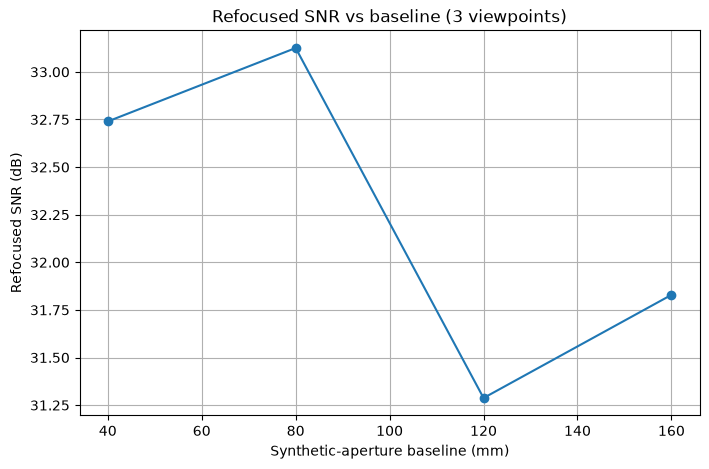

In [66]:
plt.figure(figsize=(8, 5))

plt.plot(
    df_baseline["baseline_mm"],
    df_baseline["SNR_dB"],
    marker="o"
)

plt.xlabel("Synthetic-aperture baseline (mm)")
plt.ylabel("Refocused SNR (dB)")
plt.title("Refocused SNR vs baseline (3 viewpoints)")
plt.grid()

plt.show()

In [67]:
# SSIM

In [68]:
ssim_root = SESSIONS / "ssim_reference"

ssim_check = [
    "ssim_train_01",
    "ssim_holdout_01",
    "ssim_layers_3diff_01",
    "ssim_layers_3same_01",
    "ssim_layers_5obj_01"
]

for name in ssim_check:

    folder = ssim_root / name
    df = pd.read_csv(folder / "manifest.csv")

    print("\n" + "=" * 75)
    print(name)

    print("Number of frames:", len(df))
    print("Positions:", df["x_mm"].dropna().unique())
    print("Repeats:", df["repeat_index"].dropna().unique())

    print(
        "Exposure:",
        df["exposure_us_requested"].dropna().unique()
    )

    print(
        "Gain:",
        df["gain_requested"].dropna().unique()
    )

    print(
        "Reference kind:",
        df["reference_kind"].dropna().unique()
    )

    print(
        "Scene condition:",
        df["scene_condition"].dropna().unique()
    )

    print("Files:")
    for f in df["filename"]:
        print("  ", f)


ssim_train_01
Number of frames: 3
Positions: [100.]
Repeats: [1 2 3]
Exposure: [32000]
Gain: [4.]
Reference kind: <ArrowStringArray>
['single_view_proxy']
Length: 1, dtype: str
Scene condition: <ArrowStringArray>
['textured']
Length: 1, dtype: str
Files:
   raw/step_001_x+0100.000mm_cycle01_rep001.dng
   raw/step_001_x+0100.000mm_cycle01_rep002.dng
   raw/step_001_x+0100.000mm_cycle01_rep003.dng

ssim_holdout_01
Number of frames: 3
Positions: [100.]
Repeats: [1 2 3]
Exposure: [32000]
Gain: [4.]
Reference kind: <ArrowStringArray>
['single_view_proxy']
Length: 1, dtype: str
Scene condition: <ArrowStringArray>
['textured']
Length: 1, dtype: str
Files:
   raw/step_001_x+0100.000mm_cycle01_rep001.dng
   raw/step_001_x+0100.000mm_cycle01_rep002.dng
   raw/step_001_x+0100.000mm_cycle01_rep003.dng

ssim_layers_3diff_01
Number of frames: 3
Positions: [100.]
Repeats: [1 2 3]
Exposure: [32000]
Gain: [4.]
Reference kind: <ArrowStringArray>
['single_view_proxy']
Length: 1, dtype: str
Scene conditi

PNG count: 1


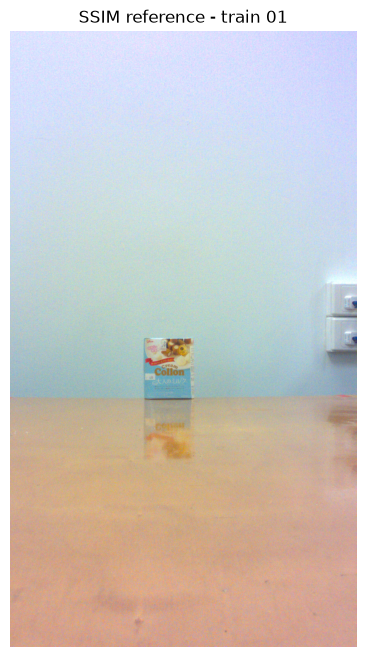

Reference PNG shape: (1200, 675, 3)


In [69]:
ssim_train_path = ssim_root / "ssim_train_01"

ssim_train_pngs = sorted(ssim_train_path.rglob("*.png"))

print("PNG count:", len(ssim_train_pngs))

reference_preview = np.array(
    Image.open(ssim_train_pngs[0]).convert("RGB")
)

plt.figure(figsize=(6, 8))
plt.imshow(reference_preview)
plt.title("SSIM reference - train 01")
plt.axis("off")
plt.show()

print("Reference PNG shape:", reference_preview.shape)

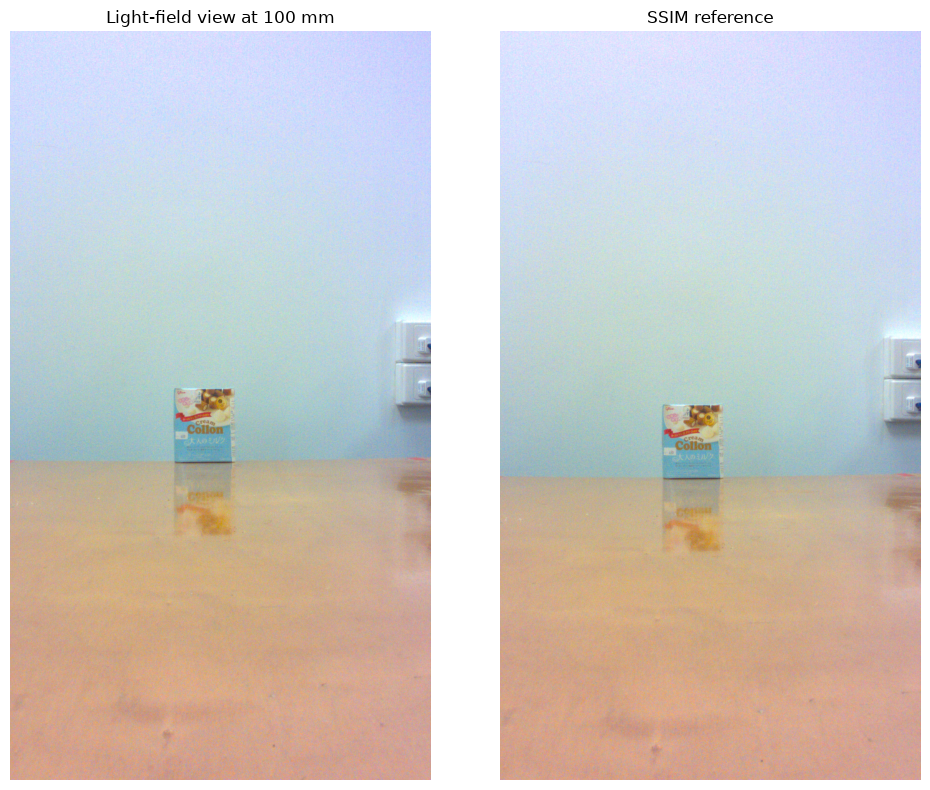

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(10, 8))

axes[0].imshow(images[5])
axes[0].set_title("Light-field view at 100 mm")
axes[0].axis("off")

axes[1].imshow(reference_preview)
axes[1].set_title("SSIM reference")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [71]:
from skimage.metrics import structural_similarity as ssim
print("SSIM imported successfully")

SSIM imported successfully


In [72]:
ssim_train_path = ssim_root / "ssim_train_01"
ssim_manifest = pd.read_csv(ssim_train_path / "manifest.csv")

reference_imgs = []

for _, row in ssim_manifest.sort_values("repeat_index").iterrows():
    path = ssim_train_path / row["filename"]
    img = load_lightfield_rgb16(path)
    reference_imgs.append(img)

reference_stack = np.stack(reference_imgs, axis=0)

# Average the 3 repeats to reduce reference noise
reference_rgb = np.mean(reference_stack, axis=0)

print("Reference stack shape:", reference_stack.shape)
print("Reference mean shape:", reference_rgb.shape)

Reference stack shape: (3, 1920, 1080, 3)
Reference mean shape: (1920, 1080, 3)


In [73]:
refocused_outputs = []

for rep in [1, 2, 3]:
    output = refocus_float_valid(
        raw_sets[rep],
        x_positions,
        raw_slope
    )
    refocused_outputs.append(output)

refocused_mean = np.mean(
    np.stack(refocused_outputs, axis=0),
    axis=0
)

print("Refocused mean shape:", refocused_mean.shape)

Refocused mean shape: (1920, 1080, 3)


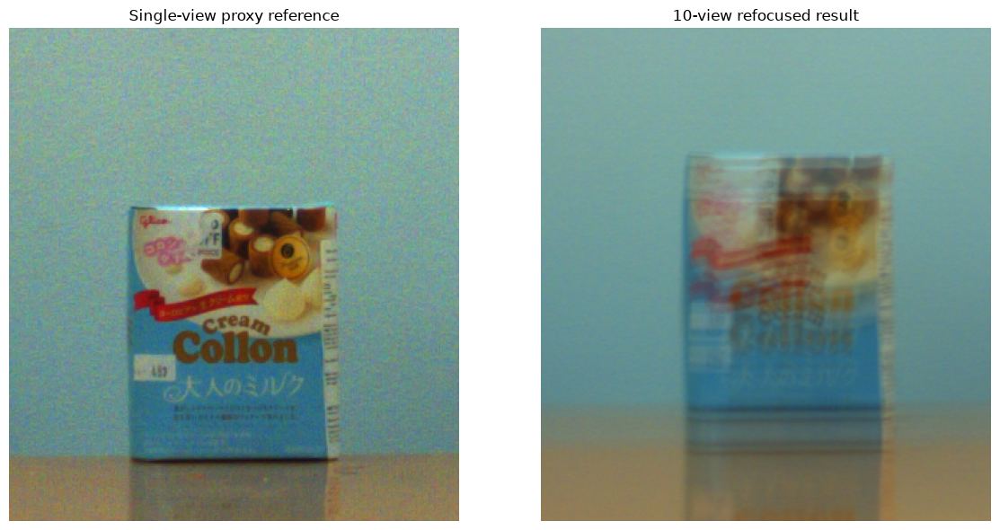

In [74]:
margin = 80

ax1 = max(raw_roi_x1 - margin, 0)
ax2 = min(raw_roi_x2 + margin, reference_rgb.shape[1])

ay1 = max(raw_roi_y1 - margin, 0)
ay2 = min(raw_roi_y2 + margin, reference_rgb.shape[0])

reference_roi_large = reference_rgb[ay1:ay2, ax1:ax2]
refocused_roi_large = refocused_mean[ay1:ay2, ax1:ax2]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(np.clip(reference_roi_large / 65535.0, 0, 1))
axes[0].set_title("Single-view proxy reference")
axes[0].axis("off")

axes[1].imshow(np.clip(refocused_roi_large / 65535.0, 0, 1))
axes[1].set_title("10-view refocused result")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [75]:
# Convert large ROIs to grayscale float32
ref_gray = cv2.cvtColor(
    np.clip(reference_roi_large / 256.0, 0, 255).astype(np.uint8),
    cv2.COLOR_RGB2GRAY
).astype(np.float32)

refocused_gray = cv2.cvtColor(
    np.clip(refocused_roi_large / 256.0, 0, 255).astype(np.uint8),
    cv2.COLOR_RGB2GRAY
).astype(np.float32)

# Estimate translation using phase correlation
(shift_x, shift_y), response = cv2.phaseCorrelate(
    refocused_gray,
    ref_gray
)

print(f"Estimated shift x = {shift_x:.3f} px")
print(f"Estimated shift y = {shift_y:.3f} px")
print(f"Phase correlation response = {response:.4f}")

Estimated shift x = -0.071 px
Estimated shift y = 0.469 px
Phase correlation response = 0.2589


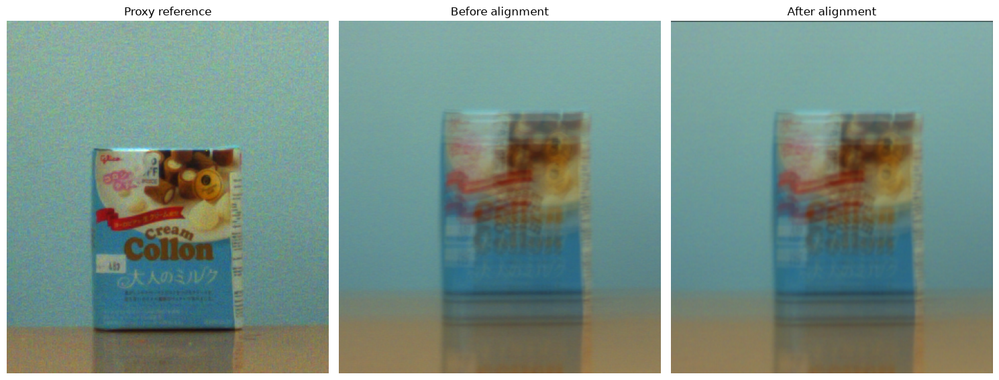

In [76]:
h_roi, w_roi = refocused_roi_large.shape[:2]

M = np.float32([
    [1, 0, shift_x],
    [0, 1, shift_y]
])

aligned_refocused = cv2.warpAffine(
    refocused_roi_large.astype(np.float32),
    M,
    (w_roi, h_roi),
    flags=cv2.INTER_LINEAR,
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=0
)

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

axes[0].imshow(np.clip(reference_roi_large / 65535.0, 0, 1))
axes[0].set_title("Proxy reference")
axes[0].axis("off")

axes[1].imshow(np.clip(refocused_roi_large / 65535.0, 0, 1))
axes[1].set_title("Before alignment")
axes[1].axis("off")

axes[2].imshow(np.clip(aligned_refocused / 65535.0, 0, 1))
axes[2].set_title("After alignment")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [77]:
crop_margin = 20

ref_eval = reference_roi_large[
    crop_margin:-crop_margin,
    crop_margin:-crop_margin
]

aligned_eval = aligned_refocused[
    crop_margin:-crop_margin,
    crop_margin:-crop_margin
]

# Convert to grayscale
ref_eval_gray = cv2.cvtColor(
    np.clip(ref_eval / 256.0, 0, 255).astype(np.uint8),
    cv2.COLOR_RGB2GRAY
)

aligned_eval_gray = cv2.cvtColor(
    np.clip(aligned_eval / 256.0, 0, 255).astype(np.uint8),
    cv2.COLOR_RGB2GRAY
)

ssim_value = ssim(
    ref_eval_gray,
    aligned_eval_gray,
    data_range=255
)

print(f"10-view refocused SSIM = {ssim_value:.4f}")

10-view refocused SSIM = 0.5999


In [78]:
def evaluate_ssim_against_reference(
    test_rgb,
    reference_rgb,
    roi_bounds,
    align=True,
    crop_margin=20
):
    """
    Compare a test image against the single-view proxy reference.

    roi_bounds = (x1, x2, y1, y2)
    Returns SSIM and estimated translation.
    """

    x1_, x2_, y1_, y2_ = roi_bounds

    test_roi = test_rgb[y1_:y2_, x1_:x2_].astype(np.float32)
    ref_roi = reference_rgb[y1_:y2_, x1_:x2_].astype(np.float32)

    shift_x = 0.0
    shift_y = 0.0
    response = np.nan

    if align:
        test_gray_align = cv2.cvtColor(
            np.clip(test_roi / 256.0, 0, 255).astype(np.uint8),
            cv2.COLOR_RGB2GRAY
        ).astype(np.float32)

        ref_gray_align = cv2.cvtColor(
            np.clip(ref_roi / 256.0, 0, 255).astype(np.uint8),
            cv2.COLOR_RGB2GRAY
        ).astype(np.float32)

        (shift_x, shift_y), response = cv2.phaseCorrelate(
            test_gray_align,
            ref_gray_align
        )

        h, w = test_roi.shape[:2]

        M = np.float32([
            [1, 0, shift_x],
            [0, 1, shift_y]
        ])

        test_roi = cv2.warpAffine(
            test_roi,
            M,
            (w, h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=0
        )

    # Remove boundaries potentially affected by translation
    ref_eval = ref_roi[
        crop_margin:-crop_margin,
        crop_margin:-crop_margin
    ]

    test_eval = test_roi[
        crop_margin:-crop_margin,
        crop_margin:-crop_margin
    ]

    ref_gray = cv2.cvtColor(
        np.clip(ref_eval / 256.0, 0, 255).astype(np.uint8),
        cv2.COLOR_RGB2GRAY
    )

    test_gray = cv2.cvtColor(
        np.clip(test_eval / 256.0, 0, 255).astype(np.uint8),
        cv2.COLOR_RGB2GRAY
    )

    score = ssim(
        ref_gray,
        test_gray,
        data_range=255
    )

    return score, shift_x, shift_y, response

In [79]:
ssim_roi_bounds = (
    ax1,
    ax2,
    ay1,
    ay2
)

print("SSIM ROI:", ssim_roi_bounds)

SSIM ROI: (328, 664, 824, 1192)


In [80]:
ssim_view_results = []

for n_views, idx in view_count_indices.items():

    outputs = []

    for rep in [1, 2, 3]:

        selected_images = [raw_sets[rep][i] for i in idx]
        selected_x = np.array(
            [x_positions[i] for i in idx],
            dtype=np.float32
        )

        if n_views == 1:
            output = selected_images[0]
        else:
            output = refocus_float_valid(
                selected_images,
                selected_x,
                raw_slope
            )

        outputs.append(output)

    # Average the 3 repeat outputs
    output_mean = np.mean(
        np.stack(outputs, axis=0),
        axis=0
    )

    score, dx, dy, response = evaluate_ssim_against_reference(
        output_mean,
        reference_rgb,
        ssim_roi_bounds
    )

    baseline = (
        float(
            max(x_positions[i] for i in idx)
            - min(x_positions[i] for i in idx)
        )
        if n_views > 1
        else 0.0
    )

    ssim_view_results.append({
        "n_views": n_views,
        "baseline_mm": baseline,
        "indices_used": idx,
        "SSIM": score,
        "align_dx_px": dx,
        "align_dy_px": dy,
        "align_response": response
    })

df_ssim_views = pd.DataFrame(ssim_view_results)

display(df_ssim_views)

,n_views,baseline_mm,indices_used,SSIM,align_dx_px,align_dy_px,align_response
0,1,0.0,[5],0.552022,0.066213,0.455236,0.159070
1,3,180.0,"[0, 4, 9]",0.558624,-0.216574,0.492625,0.190553
2,5,180.0,"[0, 2, 4, 7, 9]",0.581270,-0.001441,0.550858,0.233007
3,7,180.0,"[0, 2, 3, 4, 6, 8, 9]",0.594004,0.003874,0.477702,0.270546
4,10,180.0,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.599870,-0.071477,0.469212,0.258897


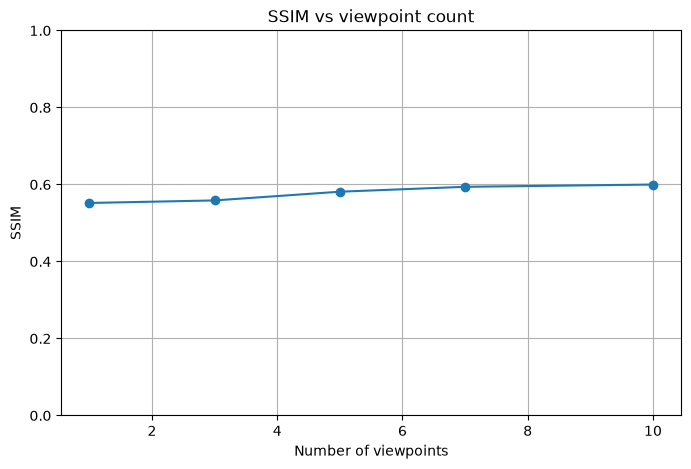

In [81]:
plt.figure(figsize=(8, 5))

plt.plot(
    df_ssim_views["n_views"],
    df_ssim_views["SSIM"],
    marker="o"
)

plt.xlabel("Number of viewpoints")
plt.ylabel("SSIM")
plt.title("SSIM vs viewpoint count")
plt.ylim(0, 1)
plt.grid()

plt.show()

In [82]:
ssim_baseline_results = []

for baseline_mm, idx in baseline_configs.items():

    outputs = []

    for rep in [1, 2, 3]:

        selected_images = [raw_sets[rep][i] for i in idx]

        selected_x = np.array(
            [x_positions[i] for i in idx],
            dtype=np.float32
        )

        output = refocus_float_valid(
            selected_images,
            selected_x,
            raw_slope
        )

        outputs.append(output)

    output_mean = np.mean(
        np.stack(outputs, axis=0),
        axis=0
    )

    score, dx, dy, response = evaluate_ssim_against_reference(
        output_mean,
        reference_rgb,
        ssim_roi_bounds
    )

    ssim_baseline_results.append({
        "baseline_mm": baseline_mm,
        "indices_used": idx,
        "SSIM": score,
        "align_dx_px": dx,
        "align_dy_px": dy,
        "align_response": response
    })

df_ssim_baseline = pd.DataFrame(ssim_baseline_results)

display(df_ssim_baseline)

,baseline_mm,indices_used,SSIM,align_dx_px,align_dy_px,align_response
0,40,"[4, 5, 6]",0.591612,0.058338,0.441380,0.223102
1,80,"[3, 5, 7]",0.603923,0.110770,0.469039,0.227774
2,120,"[2, 5, 8]",0.600203,0.154511,0.160764,0.223192
3,160,"[1, 5, 9]",0.592531,-0.010721,0.481423,0.208614


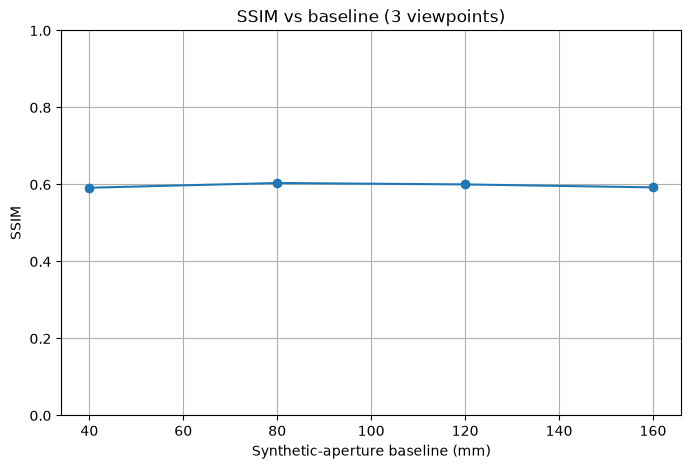

In [83]:
plt.figure(figsize=(8, 5))

plt.plot(
    df_ssim_baseline["baseline_mm"],
    df_ssim_baseline["SSIM"],
    marker="o"
)

plt.xlabel("Synthetic-aperture baseline (mm)")
plt.ylabel("SSIM")
plt.title("SSIM vs baseline (3 viewpoints)")
plt.ylim(0, 1)
plt.grid()

plt.show()

In [84]:
targets_df = pd.read_csv(ROOT / "targets.csv")

print("targets.csv shape:", targets_df.shape)
print("Columns:", list(targets_df.columns))

display(targets_df)

targets.csv shape: (14, 10)
Columns: ['target_id', 'description', 'depth_mm', 'depth_uncertainty_mm', 'depth_reference', 'material', 'surface_finish', 'printed_texture', 'reflectivity_notes', 'plane_notes']


,target_id,description,depth_mm,depth_uncertainty_mm,depth_reference,material,surface_finish,printed_texture,reflectivity_notes,plane_notes
0,GEOMETRY_GRID,Circular patterned calibration target,1808,0.5,Front of lens at x=100 mm,Printed target,Acrylic/Smoooth and slightly reflective,Radial circular pattern,Slightly Reflective,Geometry sweep; Uncertainty is +/-0.5 mm ruler...
1,CAL_01,Blue Cream Collon box,1810,0.5,Front of lens at x=100 mm,Printed product packaging,Smooth,Product graphics,Not Reflective,Calibration train depth corrected after remeas...
2,VAL_01,Blue Cream Collon box,1300,0.5,Front of lens at x=100 mm,Printed product packaging,Smooth,Product graphics,Not Reflective,Held-out validation depth; Uncertainty is +/-0...
3,CAL_02,Blue Cream Collon box,1100,0.5,Front of lens at x=100 mm,Printed product packaging,Smooth,Product graphics,Not Reflective,Calibration train depth; Uncertainty is +/-0.5...
4,VAL_02,Blue Cream Collon box,1500,0.5,Front of lens at x=100 mm,Printed product packaging,Smooth,Product graphics,Not Reflective,Held-out validation depth; Uncertainty is +/-0...
5,CAL_03,Blue Cream Collon box,1400,0.5,Front of lens at x=100 mm,Printed product packaging,Smooth,Product graphics,Not Reflective,Calibration train depth; Uncertainty is +/-0.5...
6,VAL_03,Blue Cream Collon box,1200,0.5,Front of lens at x=100 mm,Printed product packaging,Smooth,Product graphics,Not Reflective,Held-out validation depth; Uncertainty is +/-0...
7,CAL_04,Blue Cream Collon box,1600,0.5,Front of lens at x=100 mm,Printed product packaging,Smooth,Product graphics,Not Reflective,Calibration train depth; Uncertainty is +/-0.5...
8,VAL_04,Blue Cream Collon box,1700,0.5,Front of lens at x=100 mm,Printed product packaging,Smooth,Product graphics,Not Reflective,Held-out validation depth; Uncertainty is +/-0...
9,FIVE_LEFT_01,Five-object scene box 1 leftmost,1400,0.5,Front of lens at x=100 mm,Product packaging,Smooth,Product graphics,Not Reflective,lf_layers_5obj_01 left-to-right position 1; Un...


In [85]:
depth_sessions = [
    "lf_train_01",
    "lf_train_02",
    "lf_train_03",
    "lf_train_04",
    "lf_holdout_01",
    "lf_holdout_02",
    "lf_holdout_03",
    "lf_holdout_04"
]

for name in depth_sessions:
    folder = lightfield_root / name
    df = pd.read_csv(folder / "manifest.csv")

    print("\n" + "=" * 70)
    print(name)

    print("Scene condition:",
          df["scene_condition"].dropna().unique())

    print("Notes:",
          df["notes"].dropna().unique())

    print("Positions:",
          sorted(df["x_mm"].dropna().unique()))


lf_train_01
Scene condition: <ArrowStringArray>
['textured']
Length: 1, dtype: str
Notes: []
Positions: [np.float64(0.0), np.float64(20.0), np.float64(40.0), np.float64(60.0), np.float64(80.0), np.float64(100.0), np.float64(120.0), np.float64(140.0), np.float64(160.0), np.float64(180.0)]

lf_train_02
Scene condition: <ArrowStringArray>
['textured']
Length: 1, dtype: str
Notes: []
Positions: [np.float64(0.0), np.float64(20.0), np.float64(40.0), np.float64(60.0), np.float64(80.0), np.float64(100.0), np.float64(120.0), np.float64(140.0), np.float64(160.0), np.float64(180.0)]

lf_train_03
Scene condition: <ArrowStringArray>
['textured']
Length: 1, dtype: str
Notes: []
Positions: [np.float64(0.0), np.float64(20.0), np.float64(40.0), np.float64(60.0), np.float64(80.0), np.float64(100.0), np.float64(120.0), np.float64(140.0), np.float64(160.0), np.float64(180.0)]

lf_train_04
Scene condition: <ArrowStringArray>
['textured']
Length: 1, dtype: str
Notes: []
Positions: [np.float64(0.0), np.floa

In [86]:
depth_ground_truth = {
    "lf_train_01": 1810.0,
    "lf_train_02": 1100.0,
    "lf_train_03": 1400.0,
    "lf_train_04": 1600.0,

    "lf_holdout_01": 1300.0,
    "lf_holdout_02": 1500.0,
    "lf_holdout_03": 1200.0,
    "lf_holdout_04": 1700.0
}

for name, depth in depth_ground_truth.items():
    print(f"{name:15s} -> {depth:.0f} mm")

lf_train_01     -> 1810 mm
lf_train_02     -> 1100 mm
lf_train_03     -> 1400 mm
lf_train_04     -> 1600 mm
lf_holdout_01   -> 1300 mm
lf_holdout_02   -> 1500 mm
lf_holdout_03   -> 1200 mm
lf_holdout_04   -> 1700 mm


In [87]:
def estimate_disparity_slope(session_name):
    folder = lightfield_root / session_name

    pngs = sorted(folder.rglob("*.png"))

    if len(pngs) != 10:
        raise ValueError(
            f"{session_name}: expected 10 PNGs, found {len(pngs)}"
        )

    imgs = [
        np.array(Image.open(f).convert("RGB"))
        for f in pngs
    ]

    # Use the central view (100 mm) as template source
    ref_img = imgs[5]

    # ROI around the Collon box
    # Chosen large enough to accommodate the different train/holdout depths
    tx1, tx2 = 235, 390
    ty1, ty2 = 535, 720

    template = ref_img[ty1:ty2, tx1:tx2]
    template_gray = cv2.cvtColor(
        template,
        cv2.COLOR_RGB2GRAY
    )

    camera_positions = np.arange(
        0, 200, 20,
        dtype=np.float32
    )

    rows = []

    for i, img in enumerate(imgs):

        gray = cv2.cvtColor(
            img,
            cv2.COLOR_RGB2GRAY
        )

        result = cv2.matchTemplate(
            gray,
            template_gray,
            cv2.TM_CCOEFF_NORMED
        )

        _, max_val, _, max_loc = cv2.minMaxLoc(result)

        x_match, y_match = max_loc

        rows.append({
            "view": i + 1,
            "camera_x_mm": camera_positions[i],
            "object_x_px": x_match,
            "object_y_px": y_match,
            "match_score": max_val
        })

    match_df_session = pd.DataFrame(rows)

    slope_, intercept_ = np.polyfit(
        match_df_session["camera_x_mm"],
        match_df_session["object_x_px"],
        1
    )

    prediction = (
        slope_ * match_df_session["camera_x_mm"]
        + intercept_
    )

    ss_res = np.sum(
        (match_df_session["object_x_px"] - prediction) ** 2
    )

    ss_tot = np.sum(
        (
            match_df_session["object_x_px"]
            - match_df_session["object_x_px"].mean()
        ) ** 2
    )

    r2_ = 1 - ss_res / ss_tot

    return {
        "session": session_name,
        "depth_mm": depth_ground_truth[session_name],
        "slope_px_per_mm": slope_,
        "abs_slope": abs(slope_),
        "intercept_px": intercept_,
        "R2": r2_,
        "min_match_score": match_df_session["match_score"].min()
    }

In [88]:
depth_results = []

for session_name in depth_ground_truth.keys():
    try:
        result = estimate_disparity_slope(session_name)
        depth_results.append(result)

    except Exception as e:
        print(session_name, "ERROR:", e)

df_depth_slopes = pd.DataFrame(depth_results)

display(df_depth_slopes)

,session,depth_mm,slope_px_per_mm,abs_slope,intercept_px,R2,min_match_score
0,lf_train_01,1810.0,-1.010303,1.010303,334.727273,0.999760,0.968620
1,lf_train_02,1100.0,-1.651818,1.651818,399.563636,0.999975,0.963406
2,lf_train_03,1400.0,-1.294242,1.294242,363.381818,0.999931,0.971547
3,lf_train_04,1600.0,-1.136061,1.136061,347.945455,0.999878,0.967141
4,lf_holdout_01,1300.0,-1.392424,1.392424,373.418182,0.999953,0.970394
5,lf_holdout_02,1500.0,-1.206970,1.206970,354.927273,0.999906,0.974862
6,lf_holdout_03,1200.0,-1.510303,1.510303,385.127273,0.999972,0.971501
7,lf_holdout_04,1700.0,-1.063030,1.063030,340.672727,0.999922,0.970278


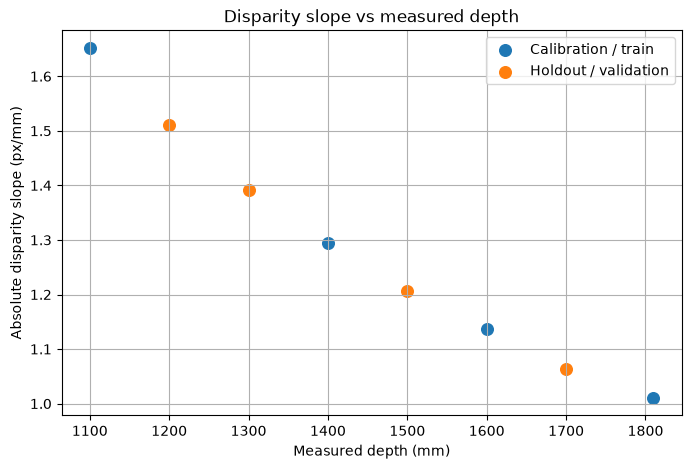

In [89]:
plt.figure(figsize=(8, 5))

train_mask = df_depth_slopes["session"].str.contains("train")
holdout_mask = df_depth_slopes["session"].str.contains("holdout")

plt.scatter(
    df_depth_slopes.loc[train_mask, "depth_mm"],
    df_depth_slopes.loc[train_mask, "abs_slope"],
    label="Calibration / train",
    s=70
)

plt.scatter(
    df_depth_slopes.loc[holdout_mask, "depth_mm"],
    df_depth_slopes.loc[holdout_mask, "abs_slope"],
    label="Holdout / validation",
    s=70
)

plt.xlabel("Measured depth (mm)")
plt.ylabel("Absolute disparity slope (px/mm)")
plt.title("Disparity slope vs measured depth")
plt.grid()
plt.legend()

plt.show()

In [90]:
train_df = df_depth_slopes[
    df_depth_slopes["session"].str.contains("train")
].copy()

holdout_df = df_depth_slopes[
    df_depth_slopes["session"].str.contains("holdout")
].copy()

# Calibration variable: inverse depth
x_train = 1.0 / train_df["depth_mm"].values
y_train = train_df["abs_slope"].values

# Fit: slope = a * (1 / depth) + b
a_cal, b_cal = np.polyfit(
    x_train,
    y_train,
    1
)

print(f"Calibration model:")
print(f"|disparity slope| = {a_cal:.6f} / depth + {b_cal:.6f}")

Calibration model:
|disparity slope| = 1802.494583 / depth + 0.010971


In [91]:
pred_train_slope = (
    a_cal / train_df["depth_mm"].values
    + b_cal
)

ss_res = np.sum(
    (train_df["abs_slope"].values - pred_train_slope) ** 2
)

ss_tot = np.sum(
    (
        train_df["abs_slope"].values
        - train_df["abs_slope"].mean()
    ) ** 2
)

calibration_r2 = 1 - ss_res / ss_tot

print(f"Calibration R² = {calibration_r2:.6f}")

Calibration R² = 0.999840


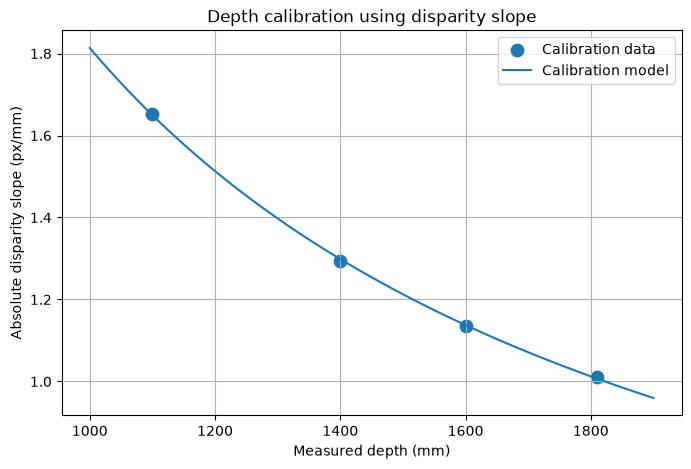

In [92]:
depth_curve = np.linspace(
    1000,
    1900,
    300
)

slope_curve = (
    a_cal / depth_curve
    + b_cal
)

plt.figure(figsize=(8, 5))

plt.scatter(
    train_df["depth_mm"],
    train_df["abs_slope"],
    s=80,
    label="Calibration data"
)

plt.plot(
    depth_curve,
    slope_curve,
    label="Calibration model"
)

plt.xlabel("Measured depth (mm)")
plt.ylabel("Absolute disparity slope (px/mm)")
plt.title("Depth calibration using disparity slope")
plt.grid()
plt.legend()

plt.show()

In [93]:
def estimate_depth_from_slope(slope_abs):
    return a_cal / (slope_abs - b_cal)

In [94]:
holdout_df["estimated_depth_mm"] = (
    holdout_df["abs_slope"]
    .apply(estimate_depth_from_slope)
)

holdout_df["error_mm"] = (
    holdout_df["estimated_depth_mm"]
    - holdout_df["depth_mm"]
)

holdout_df["abs_error_mm"] = np.abs(
    holdout_df["error_mm"]
)

holdout_df["percentage_error"] = (
    holdout_df["abs_error_mm"]
    / holdout_df["depth_mm"]
    * 100
)

display(
    holdout_df[
        [
            "session",
            "depth_mm",
            "abs_slope",
            "estimated_depth_mm",
            "error_mm",
            "abs_error_mm",
            "percentage_error"
        ]
    ]
)

,session,depth_mm,abs_slope,estimated_depth_mm,error_mm,abs_error_mm,percentage_error
4,lf_holdout_01,1300.0,1.392424,1304.781510,4.781510,4.781510,0.367808
5,lf_holdout_02,1500.0,1.206970,1507.104198,7.104198,7.104198,0.473613
6,lf_holdout_03,1200.0,1.510303,1202.198450,2.198450,2.198450,0.183204
7,lf_holdout_04,1700.0,1.063030,1713.301391,13.301391,13.301391,0.782435


In [95]:
depth_rmse = np.sqrt(
    np.mean(
        holdout_df["error_mm"] ** 2
    )
)

depth_mae = np.mean(
    holdout_df["abs_error_mm"]
)

depth_mape = np.mean(
    holdout_df["percentage_error"]
)

print(f"Holdout Depth RMSE = {depth_rmse:.3f} mm")
print(f"Holdout Depth MAE  = {depth_mae:.3f} mm")
print(f"Holdout MAPE       = {depth_mape:.3f} %")

Holdout Depth RMSE = 7.986 mm
Holdout Depth MAE  = 6.846 mm
Holdout MAPE       = 0.452 %


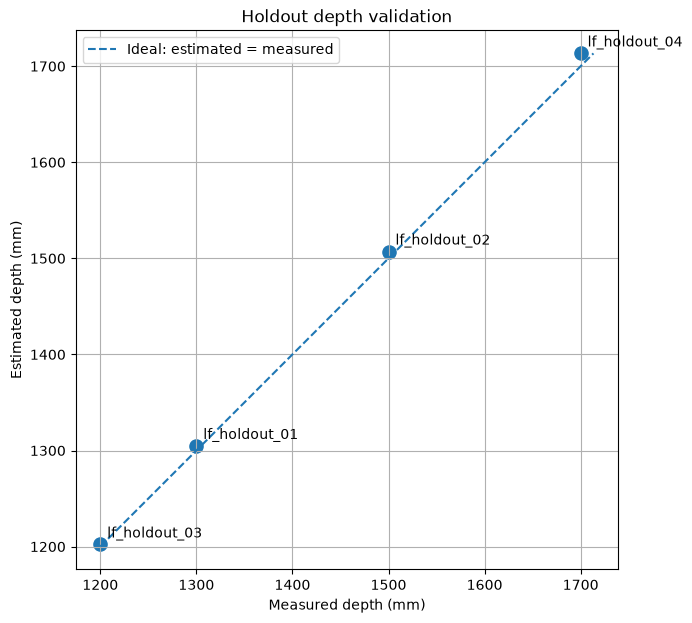

In [96]:
plt.figure(figsize=(7, 7))

plt.scatter(
    holdout_df["depth_mm"],
    holdout_df["estimated_depth_mm"],
    s=90
)

min_depth = min(
    holdout_df["depth_mm"].min(),
    holdout_df["estimated_depth_mm"].min()
)

max_depth = max(
    holdout_df["depth_mm"].max(),
    holdout_df["estimated_depth_mm"].max()
)

plt.plot(
    [min_depth, max_depth],
    [min_depth, max_depth],
    linestyle="--",
    label="Ideal: estimated = measured"
)

for _, row in holdout_df.iterrows():
    plt.annotate(
        row["session"],
        (
            row["depth_mm"],
            row["estimated_depth_mm"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Measured depth (mm)")
plt.ylabel("Estimated depth (mm)")
plt.title("Holdout depth validation")
plt.grid()
plt.legend()
plt.axis("equal")

plt.show()

In [97]:
def estimate_disparity_slope_subset(session_name, indices):
    folder = lightfield_root / session_name

    pngs = sorted(folder.rglob("*.png"))

    imgs = [
        np.array(Image.open(f).convert("RGB"))
        for f in pngs
    ]

    ref_img = imgs[5]

    tx1, tx2 = 235, 390
    ty1, ty2 = 535, 720

    template = ref_img[ty1:ty2, tx1:tx2]
    template_gray = cv2.cvtColor(
        template,
        cv2.COLOR_RGB2GRAY
    )

    camera_positions = np.arange(
        0, 200, 20,
        dtype=np.float32
    )

    selected_x = []
    selected_object_x = []
    match_scores = []

    for i in indices:
        gray = cv2.cvtColor(
            imgs[i],
            cv2.COLOR_RGB2GRAY
        )

        result = cv2.matchTemplate(
            gray,
            template_gray,
            cv2.TM_CCOEFF_NORMED
        )

        _, max_val, _, max_loc = cv2.minMaxLoc(result)

        x_match, _ = max_loc

        selected_x.append(camera_positions[i])
        selected_object_x.append(x_match)
        match_scores.append(max_val)

    slope_, intercept_ = np.polyfit(
        selected_x,
        selected_object_x,
        1
    )

    return abs(slope_), min(match_scores)

In [98]:
view_configs_depth = {
    3:  [0, 4, 9],
    5:  [0, 2, 4, 7, 9],
    7:  [0, 2, 3, 4, 6, 8, 9],
    10: list(range(10))
}

depth_vs_views_results = []

for n_views, idx in view_configs_depth.items():

    rows = []

    for session_name, gt_depth in depth_ground_truth.items():

        slope_abs, min_score = estimate_disparity_slope_subset(
            session_name,
            idx
        )

        rows.append({
            "session": session_name,
            "depth_mm": gt_depth,
            "abs_slope": slope_abs,
            "min_match_score": min_score
        })

    df_temp = pd.DataFrame(rows)

    train_temp = df_temp[
        df_temp["session"].str.contains("train")
    ].copy()

    holdout_temp = df_temp[
        df_temp["session"].str.contains("holdout")
    ].copy()

    # calibration: slope = a / depth + b
    a_temp, b_temp = np.polyfit(
        1.0 / train_temp["depth_mm"].values,
        train_temp["abs_slope"].values,
        1
    )

    holdout_temp["estimated_depth_mm"] = (
        a_temp
        / (holdout_temp["abs_slope"] - b_temp)
    )

    holdout_temp["error_mm"] = (
        holdout_temp["estimated_depth_mm"]
        - holdout_temp["depth_mm"]
    )

    rmse = np.sqrt(
        np.mean(holdout_temp["error_mm"] ** 2)
    )

    mae = np.mean(
        np.abs(holdout_temp["error_mm"])
    )

    mape = np.mean(
        np.abs(holdout_temp["error_mm"])
        / holdout_temp["depth_mm"]
        * 100
    )

    depth_vs_views_results.append({
        "n_views": n_views,
        "baseline_mm": 180,
        "RMSE_mm": rmse,
        "MAE_mm": mae,
        "MAPE_percent": mape
    })

df_depth_views = pd.DataFrame(depth_vs_views_results)

display(df_depth_views)

,n_views,baseline_mm,RMSE_mm,MAE_mm,MAPE_percent
0,3,180,9.081841,7.378745,0.499680
1,5,180,7.398501,6.500230,0.448525
2,7,180,4.981898,4.220265,0.280360
3,10,180,7.985810,6.846387,0.451765


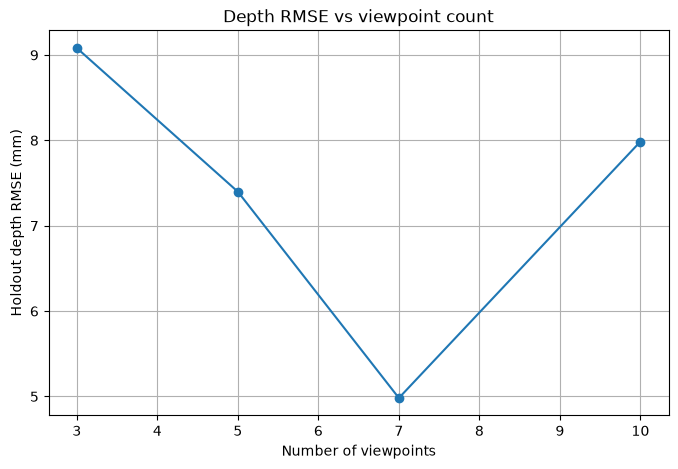

In [99]:
plt.figure(figsize=(8,5))

plt.plot(
    df_depth_views["n_views"],
    df_depth_views["RMSE_mm"],
    marker="o"
)

plt.xlabel("Number of viewpoints")
plt.ylabel("Holdout depth RMSE (mm)")
plt.title("Depth RMSE vs viewpoint count")
plt.grid()

plt.show()

In [100]:
depth_vs_baseline_results = []

for baseline_mm, idx in baseline_configs.items():

    rows = []

    for session_name, gt_depth in depth_ground_truth.items():

        slope_abs, min_score = estimate_disparity_slope_subset(
            session_name,
            idx
        )

        rows.append({
            "session": session_name,
            "depth_mm": gt_depth,
            "abs_slope": slope_abs,
            "min_match_score": min_score
        })

    df_temp = pd.DataFrame(rows)

    train_temp = df_temp[
        df_temp["session"].str.contains("train")
    ].copy()

    holdout_temp = df_temp[
        df_temp["session"].str.contains("holdout")
    ].copy()

    a_temp, b_temp = np.polyfit(
        1.0 / train_temp["depth_mm"].values,
        train_temp["abs_slope"].values,
        1
    )

    holdout_temp["estimated_depth_mm"] = (
        a_temp
        / (holdout_temp["abs_slope"] - b_temp)
    )

    holdout_temp["error_mm"] = (
        holdout_temp["estimated_depth_mm"]
        - holdout_temp["depth_mm"]
    )

    rmse = np.sqrt(
        np.mean(holdout_temp["error_mm"] ** 2)
    )

    mae = np.mean(
        np.abs(holdout_temp["error_mm"])
    )

    mape = np.mean(
        np.abs(holdout_temp["error_mm"])
        / holdout_temp["depth_mm"]
        * 100
    )

    depth_vs_baseline_results.append({
        "baseline_mm": baseline_mm,
        "n_views": 3,
        "RMSE_mm": rmse,
        "MAE_mm": mae,
        "MAPE_percent": mape
    })

df_depth_baseline = pd.DataFrame(
    depth_vs_baseline_results
)

display(df_depth_baseline)

,baseline_mm,n_views,RMSE_mm,MAE_mm,MAPE_percent
0,40,3,18.059132,15.172506,1.061271
1,80,3,9.355032,7.318142,0.475507
2,120,3,6.040329,5.547496,0.377620
3,160,3,14.948904,11.225099,0.710242


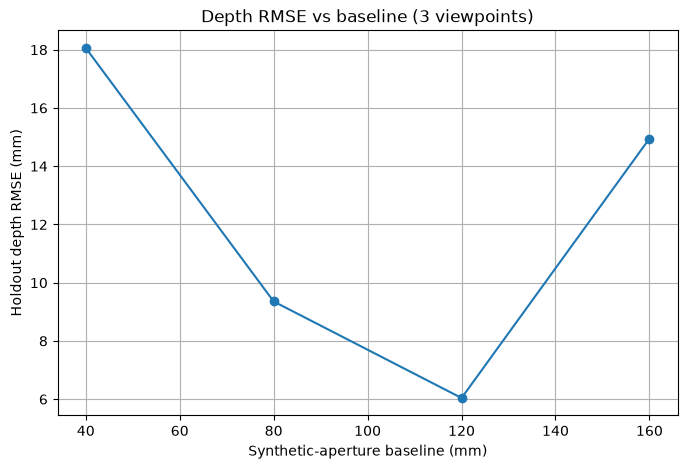

In [101]:
plt.figure(figsize=(8,5))

plt.plot(
    df_depth_baseline["baseline_mm"],
    df_depth_baseline["RMSE_mm"],
    marker="o"
)

plt.xlabel("Synthetic-aperture baseline (mm)")
plt.ylabel("Holdout depth RMSE (mm)")
plt.title("Depth RMSE vs baseline (3 viewpoints)")
plt.grid()

plt.show()